# Điều hướng notebook
Notebook chứa toàn bộ training loop và phân tích. `LAB09_TRAIN=1` khởi tạo backbone pretrained và head NER mới, train3 epochs, chọn checkpoint bằng validation rồi test. Mặc định `LAB09_TRAIN=0` tái sử dụng checkpoint thật đã train để kiểm chứng và tái tạo báo cáo, không train lại. Runtime ngoài lab09, mọi số liệu được đọc/tính từ artifacts thật. Lịch sử training được lưu riêng và không gắn nhãn là một lần training mới.

[12. Prediction Before Experiment](#lab09-section-12) · [13. Baseline](#lab09-section-13) · [14. Transformer Token Classification](#lab09-section-14) · [16. Core Implementation](#lab09-section-16) · [18. Experiment 2: Baseline vs Transformer](#lab09-section-18) · [19. Experiment 3: Entity-Level Evaluation](#lab09-section-19) · [21. Experiment 4: Entity Type Analysis](#lab09-section-21) · [22. Experiment 5: Entity Length](#lab09-section-22) · [25. Application: Information Extraction](#lab09-section-25) · [26. Mini Information Extraction Task](#lab09-section-26) · [27. Evaluation của Information Extraction](#lab09-section-27)

<a id="lab09-section-12"></a>
## 12. Prediction Before Experiment

Prediction đã ghi trong `prediction.md` trước thực nghiệm. Cấu hình cố định: seed42, 3 epochs, batch32, AdamW lr5e-5, wd0.01, warmup10%, max_length256, CUDA fp16 nếu có. Chỉ validation chọn epoch; test đánh giá sau khi chốt.

<a id="lab09-section-14"></a>
## 14. Transformer Token Classification


Backbone `distilbert/distilbert-base-cased` pretrained ngôn ngữ, không phải checkpoint fine-tuned CoNLL. Head token classification được khởi tạo mới. Không dùng `pipeline("ner")`.


In [1]:
import os, sys
sys.dont_write_bytecode = True
import json, platform, hashlib, random, importlib.metadata, time
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
import matplotlib
from baseline_ner import ROOT, RUNTIME, ART, CACHE, LABELS, TYPES, load_data, load_predictions, save_predictions, score, spans, write_json, run_baseline, run_self_checks, prediction_core
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from IPython.display import display, Image
from information_extraction import seed_all, encode_rows, predict_rows, core_demo, AutoTokenizer, AutoModelForTokenClassification, DataCollatorForTokenClassification, CHECKPOINT, MAX_LENGTH
RUN_TRAINING = os.environ.get('LAB09_TRAIN','0') == '1'
seed_all()
data = load_data(inspect=False)
print('Runtime:', RUNTIME, 'explicit retraining:', RUN_TRAINING)
print('Python:',sys.version,'platform:',platform.platform())
print('torch:',torch.__version__,'CUDA:',torch.cuda.is_available())
print('split sizes:',{s:len(v) for s,v in data.items()})
print('source revisions:',json.loads((ART/'sources.json').read_text()))

Runtime: C:\Users\tasdus_117\Desktop\NLP_runtime\lab09 explicit retraining: False
Python: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)] platform: Windows-11-10.0.26200-SP0
torch: 2.14.0+cu132 CUDA: True
split sizes: {'train': 14041, 'validation': 3250, 'test': 3453}
source revisions: {'dataset': {'repo': 'eriktks/conll2003', 'revision': 'ce85b39f9dd99f552d0739d456814e95fb6a39b0', 'files': [{'name': 'conll2003/test/0000.parquet', 'url': 'https://huggingface.co/datasets/eriktks/conll2003/resolve/ce85b39f9dd99f552d0739d456814e95fb6a39b0/conll2003/test/0000.parquet', 'bytes': 283307, 'sha256': '14f894263b4ee3563395a57b8ba4cfaabec7db4ea956ba34e2f84a19781cdc43'}, {'name': 'conll2003/train/0000.parquet', 'url': 'https://huggingface.co/datasets/eriktks/conll2003/resolve/ce85b39f9dd99f552d0739d456814e95fb6a39b0/conll2003/train/0000.parquet', 'bytes': 1227788, 'sha256': '546cbb4200311629804a65cbe19c8846f16ab1529c4da48bcc7be8c40daf29c6'}, {'name': 'conll2003/val

<a id="lab09-section-13"></a>
## 13. Baseline

Vectorizer/classifier chỉ fit train, features word/lower/prefix/suffix/casing/digits/ngữ cảnh ±1 trong cùng câu. Grid C={0.5,1,2} cố định trước lượt chạy bổ sung; chọn F1 validation cao nhất, tie chọn C nhỏ hơn; không chọn bằng test. Output word tags được chuẩn hóa IOB2 công khai trước exact span scoring, giống Transformer. Entity-level P/R/F1 và support là chỉ tiêu chính.


In [2]:
if RUN_TRAINING:
    baseline_report = run_baseline()
else:
    baseline_report = json.loads((ART/'baseline_run.json').read_text())
display(pd.DataFrame([dict(model='baseline',split=s,**baseline_report[s]) for s in ('validation','test')]))
display(pd.DataFrame([dict(C=t['C'],**t['validation']) for t in baseline_report['validation_trials']]))
print('Selected C by validation:',baseline_report['selected_C'])

,model,split,precision,recall,f1,support,tp,fp,fn
0,baseline,validation,0.831135,0.848199,0.839580,5942,5040,1024,902
1,baseline,test,0.719953,0.755135,0.737124,5648,4265,1659,1383


,C,precision,recall,f1,support,tp,fp,fn
0,0.5,0.811808,0.826153,0.818917,5942,4909,1138,1033
1,1.0,0.822889,0.839785,0.831251,5942,4990,1074,952
2,2.0,0.831135,0.848199,0.839580,5942,5040,1024,902


Selected C by validation: 2.0


<a id="lab09-section-16"></a>
## 16. Core Implementation

Helper được dùng để tránh hai phiên bản logic khác nhau giữa notebook/script/IE. Cell sau hiển thị core source đang chạy; training loop dùng loss của token head (cross entropy ignore_index=-100), backward, gradient clipping, optimizer và validation mỗi epoch.


In [3]:
def train(epochs=3, batch_size=32, seed=42, train_limit=None):
    seed_all(seed)
    data = load_data()
    train_rows = data['train'] if train_limit is None else data['train'][:train_limit]
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    tokenizer = AutoTokenizer.from_pretrained(CACHE / 'backbone', local_files_only=True, use_fast=True)
    model = AutoModelForTokenClassification.from_pretrained(
        CACHE / 'backbone', local_files_only=True, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id={t: i for i, t in enumerate(LABELS)})
    model.to(device)
    records, mapping = encode_rows(train_rows, tokenizer)
    loader = DataLoader(records, batch_size=batch_size, shuffle=True, num_workers=0,
                        generator=torch.Generator().manual_seed(seed),
                        collate_fn=DataCollatorForTokenClassification(tokenizer))
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01)
    total_steps, step = len(loader) * epochs, 0
    warmup = max(1, int(total_steps * 0.1))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min(s / warmup, max(0, (total_steps - s) / max(1, total_steps - warmup))))
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    history, best, best_epoch = [], -1.0, None
    prediction_hash = hashlib.sha256(prediction_core((ROOT/'prediction.md').read_text(encoding='utf8')).encode()).hexdigest()
    start_time = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = count = 0
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
                loss = model(**batch).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            n = int((batch['labels'] != -100).sum())
            loss_sum += float(loss.detach()) * n
            count += n
            if step % 100 == 0:
                print(f'epoch={epoch} step={step}/{total_steps} loss={loss_sum/count:.4f}', flush=True)
        pred = predict_rows(model, tokenizer, data['validation'])
        val = score([r['tags'] for r in data['validation']], pred)
        history.append(dict(epoch=epoch, train_loss=loss_sum/count, validation=val,
                            elapsed_seconds=time.perf_counter() - start_time))
        print(history[-1], flush=True)
        if val['f1'] > best:
            best, best_epoch = val['f1'], epoch
            model.save_pretrained(CHECKPOINT)
            tokenizer.save_pretrained(CHECKPOINT)
        write_json(ART / 'training_history.json', history)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    manifest = json.loads((ART / 'sources.json').read_text())
    report = dict(model='transformer', model_id=manifest['model']['repo'], model_revision=manifest['model']['revision'],
                  dataset_revision=manifest['dataset']['revision'], seed=seed, epochs=epochs,
                  batch_size=batch_size, learning_rate=5e-5, weight_decay=0.01, warmup_steps=warmup,
                  max_length=MAX_LENGTH, alignment='first-subtoken', chunking='complete words, non-overlapping; concatenate before scoring',
                  train_sentences=len(train_rows), train_chunks=len(records), validation_sentences=len(data['validation']),
                  main_experiment=train_limit is None, device=str(device),
                  gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else None,
                  mixed_precision='float16' if device.type == 'cuda' else 'float32',
                  training_seconds=time.perf_counter() - start_time, best_epoch=best_epoch,
                  best_validation_f1=best, history=history, prediction_initial_sha256=prediction_hash,
                  versions={p: importlib.metadata.version(p) for p in ['torch', 'transformers', 'tokenizers', 'scikit-learn', 'numpy', 'pandas', 'pyarrow']})
    write_json(ART / 'transformer_run.json', report)
    return report


def evaluate():
    seed_all()
    data = load_data()
    tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT, local_files_only=True)
    model = AutoModelForTokenClassification.from_pretrained(CHECKPOINT, local_files_only=True)
    model.to('cuda' if torch.cuda.is_available() else 'cpu')
    report = json.loads((ART / 'transformer_run.json').read_text())
    start = time.perf_counter()
    for split in ('validation', 'test'):
        predictions = predict_rows(model, tokenizer, data[split])
        save_predictions('transformer', data[split], predictions, split)
        report[split] = score([r['tags'] for r in data[split]], predictions)
    report['evaluation_seconds'] = time.perf_counter() - start
    write_json(ART / 'transformer_run.json', report)
    write_json(ART / 'core_demo.json', core_demo(model, tokenizer, data['validation']))
    print(report['test'], flush=True)
    return report


In [4]:
if RUN_TRAINING:
    training_report = train(epochs=3,batch_size=32,seed=42)
else:
    training_report = json.loads((ART/'transformer_run.json').read_text())
display(pd.DataFrame([dict(epoch=r['epoch'],train_loss=r['train_loss'],validation_f1=r['validation']['f1'],elapsed_seconds=r['elapsed_seconds']) for r in training_report['history']]))
print('Best validation epoch:',training_report['best_epoch'])
print('Recorded training+validation seconds:',training_report['training_seconds'])

,epoch,train_loss,validation_f1,elapsed_seconds
0,1,0.247460,0.914105,33.915651
1,2,0.030849,0.933255,52.267042
2,3,0.012987,0.942459,70.952697


Best validation epoch: 3
Recorded training+validation seconds: 71.11812029999987


<a id="lab09-section-18"></a>
## 18. Experiment 2: Baseline vs Transformer

`evaluate()` chỉ load best checkpoint, không update weights. Cùng sentence IDs, words, gold với baseline. 

<a id="lab09-section-19"></a>
## 19. Experiment 3: Entity-Level Evaluation

Normalization I-X không hợp lệ thành B-X áp dụng cả hai; exact scorer sau repair, không dùng permissive partial match. Zero denominator trả 0 và luôn công bố support.


In [5]:
if RUN_TRAINING:
    report = evaluate()
else:
    report = json.loads((ART/'transformer_run.json').read_text())
print(json.dumps(report,indent=2))

{
  "model": "transformer",
  "model_id": "distilbert/distilbert-base-cased",
  "model_revision": "6ea81172465e8b0ad3fddeed32b986cdcdcffcf0",
  "dataset_revision": "ce85b39f9dd99f552d0739d456814e95fb6a39b0",
  "seed": 42,
  "epochs": 3,
  "batch_size": 32,
  "learning_rate": 5e-05,
  "weight_decay": 0.01,
  "warmup_steps": 131,
  "max_length": 256,
  "alignment": "first-subtoken",
  "chunking": "complete words, non-overlapping; concatenate before scoring",
  "train_sentences": 14041,
  "train_chunks": 14041,
  "validation_sentences": 3250,
  "main_experiment": true,
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 5060 Ti",
  "mixed_precision": "float16",
  "training_seconds": 71.11812029999987,
  "best_epoch": 3,
  "best_validation_f1": 0.9424593189062238,
  "history": [
    {
      "epoch": 1,
      "train_loss": 0.24745958484976374,
      "validation": {
        "precision": 0.9051311664741791,
        "recall": 0.9232581622349377,
        "f1": 0.9141048071315504,
        "support"

### Tokens, tensors, logits và predictions
Chỉ first-subtoken đưa về word prediction. Logits ở special/pad/continuation vẫn tồn tại nhưng không được tính như gold targets. H shape [B,T,d]; token head dùng từng vector d chiều, cho Z [B,T,9], labels [B,T].


In [6]:
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT, local_files_only=True)
model = AutoModelForTokenClassification.from_pretrained(CHECKPOINT, local_files_only=True).eval()
records, mapping = encode_rows(data['validation'][:2], tokenizer)
batch = DataCollatorForTokenClassification(tokenizer)(records)
with torch.inference_mode():
    output = model(**batch, output_hidden_states=True)
print('shapes:',{k:tuple(v.shape) for k,v in batch.items()})
print('hidden:',tuple(output.hidden_states[-1].shape),'logits:',tuple(output.logits.shape),'loss:',float(output.loss))
pred = output.logits.argmax(-1)
wids = mapping[0][3] + [None]*(batch['input_ids'].shape[1]-len(mapping[0][3]))
display(pd.DataFrame(dict(token=tokenizer.convert_ids_to_tokens(batch['input_ids'][0].tolist()),
    input_id=batch['input_ids'][0].tolist(), attention_mask=batch['attention_mask'][0].tolist(), word_id=wids,
    label_id=batch['labels'][0].tolist(), prediction=[LABELS[t] for t in pred[0].tolist()])))
print('all logits for first sentence:',output.logits[0].tolist())
print('word predictions:',[LABELS[t] for t,y in zip(pred[0].tolist(),batch['labels'][0].tolist()) if y!=-100])
assert output.logits.shape[-1] == len(LABELS)
assert (batch['labels'][batch['attention_mask']==0]==-100).all()

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

shapes: {'input_ids': (2, 37), 'token_type_ids': (2, 37), 'attention_mask': (2, 37), 'labels': (2, 37)}
hidden: (2, 37, 768) logits: (2, 37, 9) loss: 0.43203213810920715


,token,input_id,attention_mask,word_id,label_id,prediction
0,[CLS],101,1,NaN,-100,O
1,CR,15531,1,0.0,0,O
2,##IC,9741,1,0.0,-100,O
3,##KE,22441,1,0.0,-100,O
4,##T,1942,1,0.0,-100,O
5,-,118,1,1.0,0,O
6,L,149,1,2.0,3,B-PER
7,##EI,27514,1,2.0,-100,O
8,##CE,10954,1,2.0,-100,O
9,##ST,9272,1,2.0,-100,O


all logits for first sentence: [[6.2042155265808105, -0.4066057801246643, -1.2500910758972168, -0.6211969256401062, -1.2274761199951172, -0.3177230954170227, -1.1324162483215332, -0.7840725183486938, -0.6088627576828003], [9.078842163085938, -0.7570939660072327, -2.209080457687378, -0.9327954053878784, -1.9930353164672852, -0.7765596508979797, -2.1740362644195557, -1.379669427871704, -1.2806541919708252], [5.680060386657715, 0.02651474066078663, -1.7109603881835938, -0.6112411618232727, -1.6608805656433105, -0.4824231266975403, -1.9921958446502686, -1.414406418800354, -0.5430120229721069], [5.455265522003174, -0.6466744542121887, -1.007034182548523, -0.8436986804008484, -1.5016635656356812, -1.0966389179229736, -1.6925597190856934, -1.0644183158874512, 0.10319016873836517], [8.041316032409668, -0.8293912410736084, -1.6521973609924316, -1.0369763374328613, -0.9754030704498291, -1.5581719875335693, -1.74021315574646, -1.4032528400421143, -0.23223957419395447], [9.470301628112793, -0.9227

<a id="lab09-section-21"></a>
## 21. Experiment 4: Entity Type Analysis

Bảng theo PER/ORG/LOC/MISC trong output cell 13 (`analyze_results()`); [entity_metrics.csv](entity_metrics.csv).

<a id="lab09-section-22"></a>
## 22. Experiment 5: Entity Length

Length = số words annotation gốc, không phải subwords. Gold và prediction tự vào bin 1/2/3/4+ theo độ dài chính nó; span lệch độ dài sẽ tạo FP ở predicted bin và FN ở gold bin. 

### Confusion matrix cấp word-token
Confusion matrix là **word-token BIO counts**, có O, hàng gold/cột prediction; gold O→entity tag là spurious token, entity→O là missed token, không gọi đây là entity confusion matrix.


| model       | split   |   sentences |   precision |   recall |     f1 |   support |   tp |   fp |   fn |   seed |   training_seconds |
|:------------|:--------|------------:|------------:|---------:|-------:|----------:|-----:|-----:|-----:|-------:|-------------------:|
| baseline    | test    |        3453 |      0.7200 |   0.7551 | 0.7371 |      5648 | 4265 | 1659 | 1383 |     42 |            17.6967 |
| transformer | test    |        3453 |      0.8877 |   0.9053 | 0.8964 |      5648 | 5113 |  647 |  535 |     42 |            71.1181 |


,model,split,sentences,precision,recall,f1,support,tp,fp,fn,seed,training_seconds
0,baseline,test,3453,0.719953,0.755135,0.737124,5648,4265,1659,1383,42,17.696662
1,transformer,test,3453,0.887674,0.905276,0.896388,5648,5113,647,535,42,71.118120


,model,type,training_support,precision,recall,f1,support,tp,fp,fn
0,baseline,PER,6600,0.710315,0.821892,0.762041,1617,1329,542,288
1,baseline,ORG,6321,0.623049,0.624925,0.623986,1661,1038,628,623
2,baseline,LOC,7140,0.809327,0.821942,0.815586,1668,1371,323,297
3,baseline,MISC,3438,0.760462,0.750712,0.755556,702,527,166,175
4,transformer,PER,6600,0.949907,0.949907,0.949907,1617,1536,81,81
5,transformer,ORG,6321,0.849885,0.886213,0.867669,1661,1472,260,189
6,transformer,LOC,7140,0.919952,0.923261,0.921604,1668,1540,134,128
7,transformer,MISC,3438,0.766621,0.804843,0.785268,702,565,172,137


,model,length,precision,recall,f1,support,tp,fp,fn
0,baseline,1,0.664975,0.769726,0.713526,3574,2751,1386,823
1,baseline,2,0.857583,0.783221,0.818717,1776,1391,231,385
2,baseline,3,0.751773,0.449153,0.562334,236,106,35,130
3,baseline,4+,0.708333,0.274194,0.395349,62,17,7,45
4,transformer,1,0.878639,0.903470,0.890882,3574,3229,446,345
5,transformer,2,0.916104,0.916104,0.916104,1776,1627,149,149
6,transformer,3,0.838174,0.855932,0.846960,236,202,39,34
7,transformer,4+,0.808824,0.887097,0.846154,62,55,13,7


,model,group,support,exact_tp,recall
0,baseline,rare,2851,1713,0.600842
1,baseline,common,2797,2552,0.912406
2,transformer,rare,2851,2493,0.874430
3,transformer,common,2797,2620,0.936718


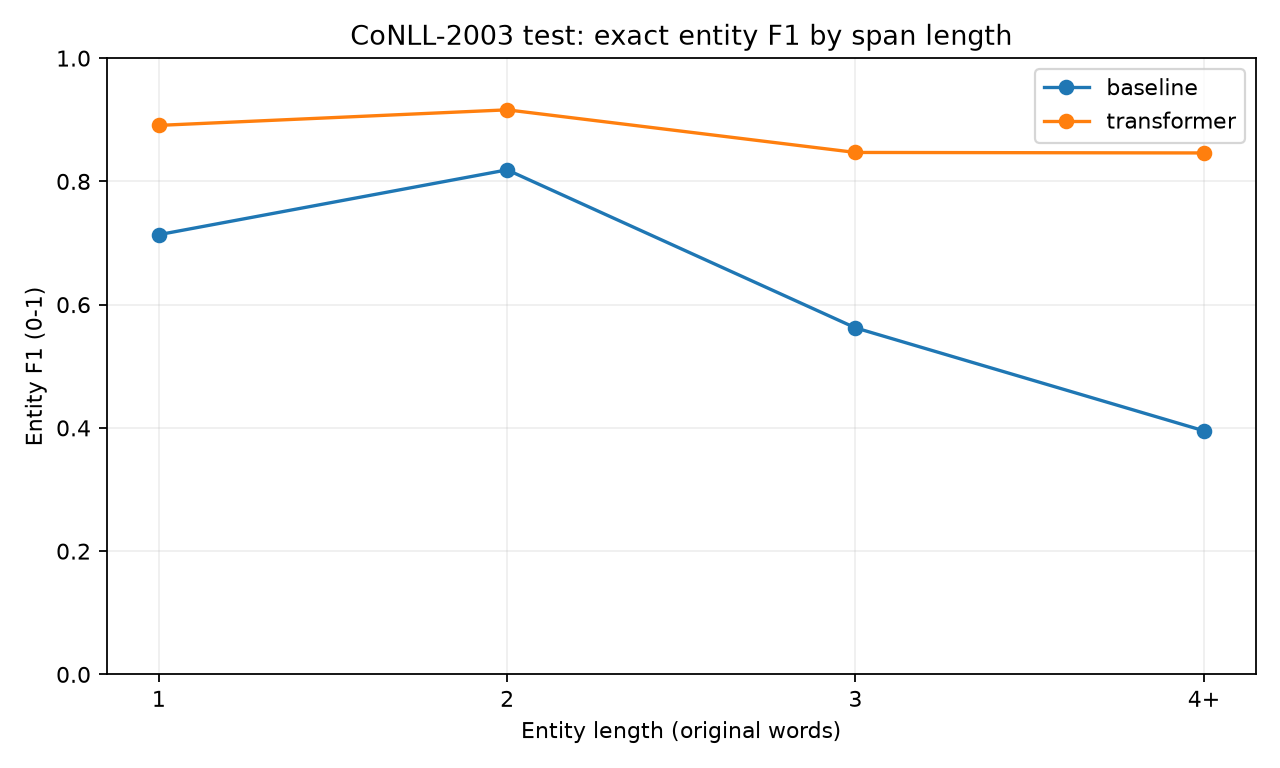

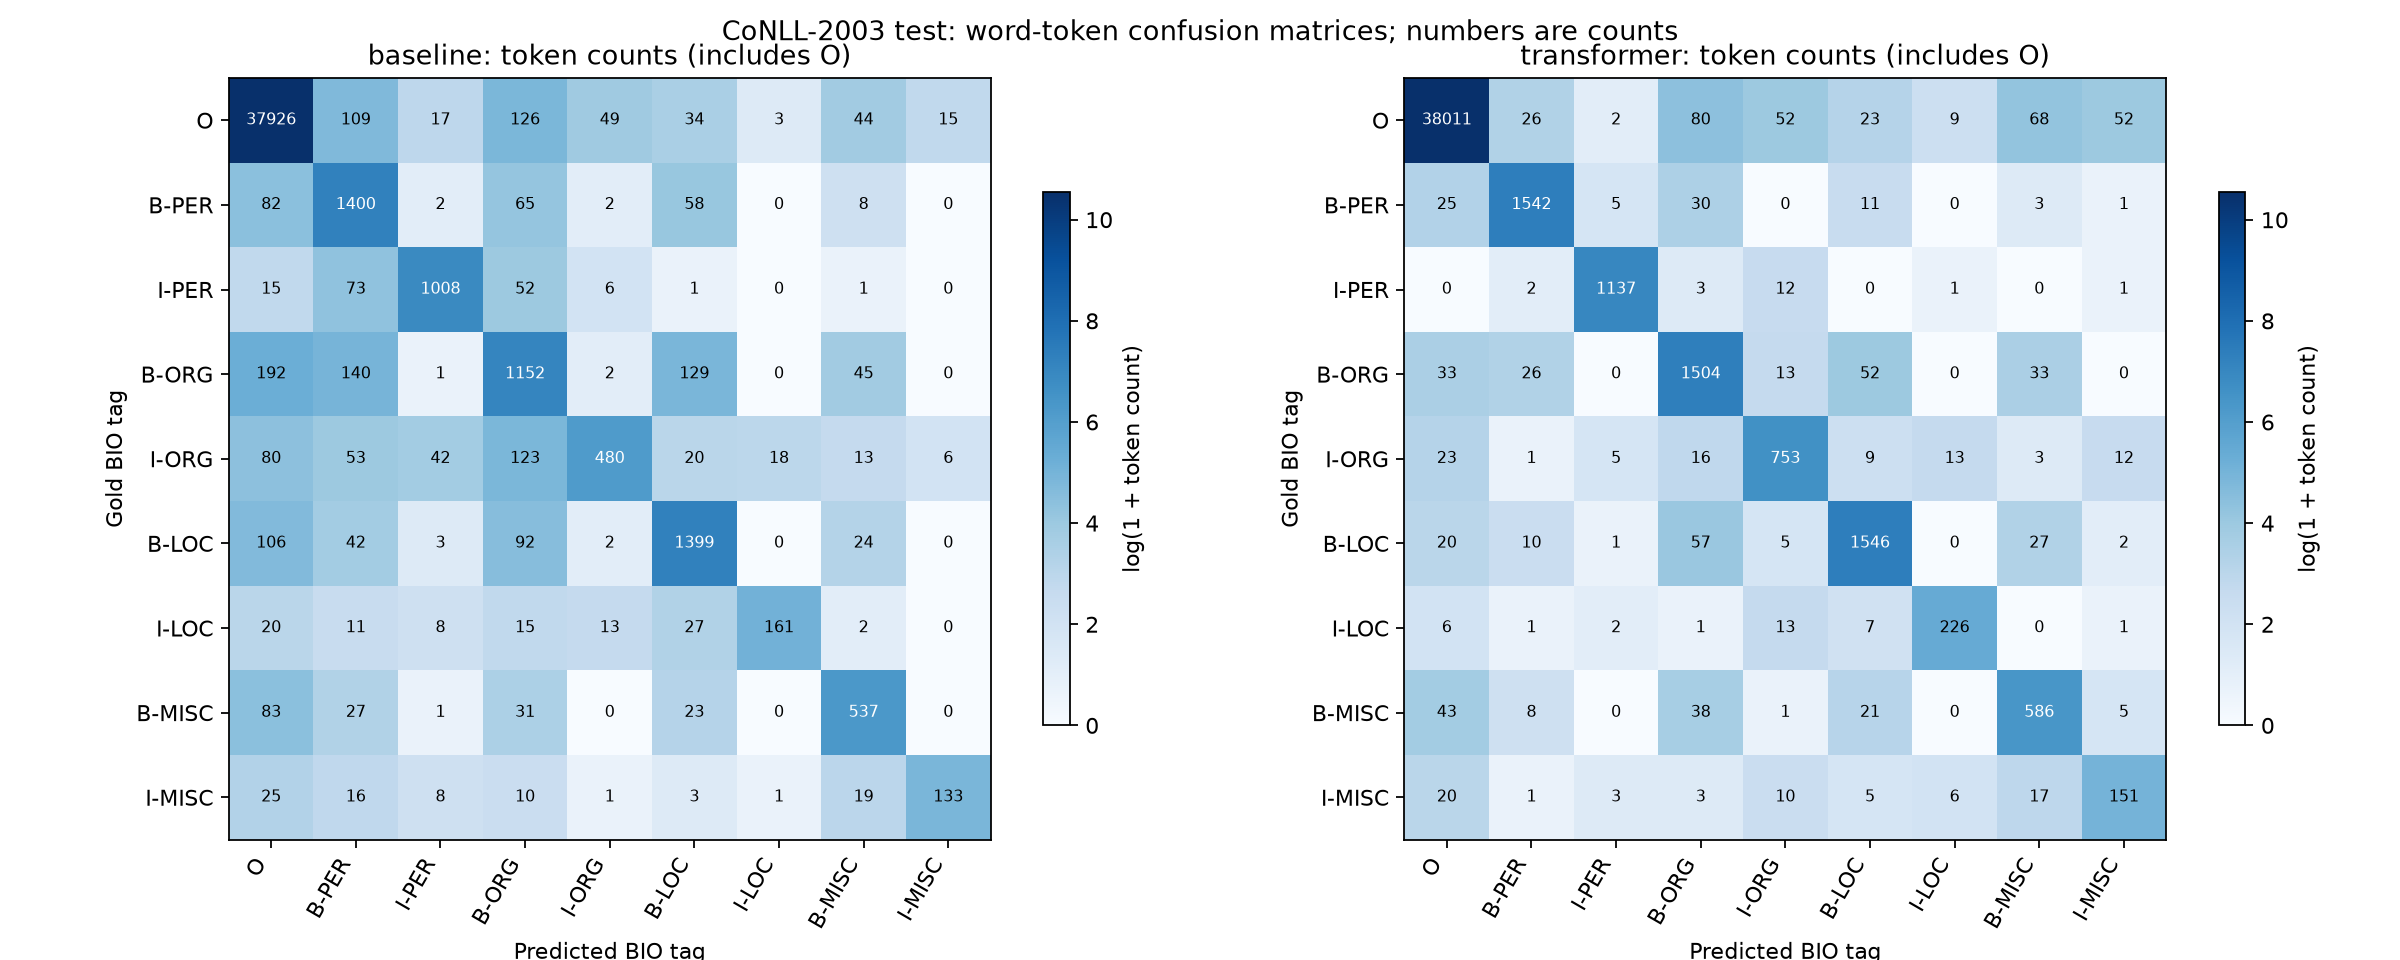

In [7]:
def surface(words, span):
    return ' '.join(words[span[0]:span[1]])


def markdown_table(rows):
    return pd.DataFrame(rows).to_markdown(index=False, floatfmt='.4f')


def analyze_results():
    data = load_data()
    models = {name: load_predictions(name) for name in ('baseline', 'transformer')}
    for rows in models.values():
        assert [(r['id'], r['words'], r['gold']) for r in rows] == [(r['id'], r['words'], r['tags']) for r in data['test']]
    results, typed, lengths, rarity_rows, pattern_rows = [], [], [], [], []
    train_counts = Counter(surface(r['words'], s).casefold() for r in data['train'] for s in spans(r['tags']))
    type_support = Counter(s[2] for r in data['train'] for s in spans(r['tags']))
    for typ in TYPES:
        items = [(r, s) for r in data['train'] for s in spans(r['tags']) if s[2] == typ]
        pattern_rows.append(dict(type=typ, training_support=len(items),
            mean_words=np.mean([s[1]-s[0] for r,s in items]),
            title_case_fraction=np.mean([surface(r['words'], s).istitle() for r,s in items]),
            all_upper_fraction=np.mean([surface(r['words'], s).isupper() for r,s in items])))
    for name, rows in models.items():
        gold, pred = [r['gold'] for r in rows], [r['pred'] for r in rows]
        run = json.loads((ART / f'{name}_run.json').read_text())
        results.append(dict(model=name, split='test', sentences=len(rows), **score(gold, pred),
                            seed=42, training_seconds=run['training_seconds']))
        for typ in TYPES:
            typed.append(dict(model=name, type=typ, training_support=type_support[typ], **score(gold, pred, entity_type=typ)))
        for length in ('1', '2', '3', '4+'):
            lengths.append(dict(model=name, length=length, **score(gold, pred, length=length)))
        for group in ('rare', 'common'):
            support = correct = 0
            for r in rows:
                ps = spans(r['pred'])
                for s in spans(r['gold']):
                    rare = train_counts[surface(r['words'], s).casefold()] <= 1
                    if rare == (group == 'rare'):
                        support += 1
                        correct += s in ps
            rarity_rows.append(dict(model=name, group=group, support=support, exact_tp=correct,
                                    recall=correct/support if support else 0.0))
    pd.DataFrame(results).to_csv(ROOT / 'results.csv', index=False)
    pd.DataFrame(typed).to_csv(ROOT / 'entity_metrics.csv', index=False)
    pd.DataFrame(lengths).to_csv(ART / 'length_metrics.csv', index=False)
    pd.DataFrame(rarity_rows).to_csv(ART / 'rarity_metrics.csv', index=False)
    pd.DataFrame(pattern_rows).to_csv(ART / 'training_patterns.csv', index=False)
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for name in models:
        values = [r for r in lengths if r['model'] == name]
        ax.plot([r['length'] for r in values], [r['f1'] for r in values], marker='o', label=name)
    ax.set(title='CoNLL-2003 test: exact entity F1 by span length', xlabel='Entity length (original words)', ylabel='Entity F1 (0-1)', ylim=(0, 1))
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(ROOT / 'entity_length_analysis.png', dpi=160)
    plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    matrices = {}
    for ax, (name, rows) in zip(axes, models.items()):
        cm = confusion_matrix([t for r in rows for t in r['gold']], [t for r in rows for t in r['pred']], labels=LABELS)
        matrices[name] = cm.tolist()
        im = ax.imshow(np.log1p(cm), cmap='Blues', vmin=0)
        for (i, j), n in np.ndenumerate(cm):
            ax.text(j, i, str(n), ha='center', va='center', fontsize=7, color='white' if np.log1p(n) > 6 else 'black')
        ax.set(xticks=range(9), yticks=range(9), xticklabels=LABELS, yticklabels=LABELS,
               title=f'{name}: token counts (includes O)', xlabel='Predicted BIO tag', ylabel='Gold BIO tag')
        plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
        fig.colorbar(im, ax=ax, label='log(1 + token count)', shrink=.7)
    fig.suptitle('CoNLL-2003 test: word-token confusion matrices; numbers are counts')
    fig.tight_layout()
    fig.savefig(ROOT / 'confusion_matrix.png', dpi=160)
    plt.close(fig)
    write_json(ART / 'confusion_counts.json', dict(labels=LABELS, matrices=matrices))
    build_errors(models['transformer'], typed, lengths, rarity_rows, pattern_rows, train_counts)
    compare = '### Kết quả đối chiếu\n\n'
    compare += 'Prediction gốc giữ nguyên trong `prediction.md`; các bảng sau được tính từ predictions thật.\n\n'
    compare += markdown_table(results) + '\n\n'
    delta = results[1]['f1'] - results[0]['f1']
    compare += f'Prediction 1: chênh lệch F1 Transformer − baseline = {delta:.4f}; ' + ('ủng hộ' if delta > 0 else 'không ủng hộ') + ' hướng dự đoán trên lần chạy này.\n\n'
    compare += markdown_table(lengths) + '\n\nPrediction 2: '
    for name in models:
        by_length = {r['length']:r['f1'] for r in lengths if r['model']==name}
        compare += f"{name}: F1 nhóm 1={by_length['1']:.4f}, 2={by_length['2']:.4f}, 3={by_length['3']:.4f}, 4+={by_length['4+']:.4f}. "
    compare += 'Nhóm 2 tốt hơn nhóm 1, trong khi 3/4+ thấp hơn nhóm 1: chỉ ủng hộ một phần, không có xu hướng giảm đơn điệu. Nhóm 4+ chỉ có 62 gold entities, cần thận trọng khi so sánh.\n\n'
    compare += markdown_table(rarity_rows) + '\n\nPrediction 3: rare = training frequency 0–1, common >=2; chỉ đo recall trên gold, không phải F1. '
    for name in models:
        r = {x['group']:x['recall'] for x in rarity_rows if x['model']==name}
        compare += f"{name}: recall rare={r['rare']:.4f}, common={r['common']:.4f}; "
    compare += 'rare thấp hơn common ở cả hai model, phù hợp hướng dự đoán trên một seed. Type, độ dài và ngữ cảnh có thể gây nhiễu. Các so sánh thể hiện quan hệ quan sát trên một seed, không chứng minh quan hệ nhân quả.\n'
    (ART / 'prediction_comparison.md').write_text(compare, encoding='utf-8')
    path = ROOT/'prediction.md'
    initial = path.read_text(encoding='utf8').split('## Đối chiếu sau thực nghiệm')[0]
    path.write_text(initial+'## Đối chiếu sau thực nghiệm\n\n'+compare,encoding='utf8')
    print(markdown_table(results))


def build_errors(rows, typed, lengths, rarity, patterns, train_counts):
    groups = {'FP': [], 'FN': [], 'boundary': []}
    all_counts = Counter()
    evidence = []
    for row in rows:
        gs, ps = spans(row['gold']), spans(row['pred'])
        all_counts['FP'] += len(ps - gs)
        all_counts['FN'] += len(gs - ps)
        def overlap(a, b):
            return a[0] < b[1] and b[0] < a[1]
        def add(group, g, p):
            if len(groups[group]) < 5:
                groups[group].append(dict(split='test', sentence_id=row['id'], text=' '.join(row['words']),
                                         gold=g, prediction=p, words=row['words'], group=group))
        for p in sorted(ps - gs):
            options = sorted([g for g in gs if overlap(g, p)])
            add('FP', options[0] if options else None, p)
        for g in sorted(gs - ps):
            options = sorted([p for p in ps if overlap(g, p)])
            add('FN', g, options[0] if options else None)
        for g in sorted(gs):
            for p in sorted(ps):
                if g[2] == p[2] and g[:2] != p[:2] and overlap(g, p):
                    all_counts['boundary'] += 1
                    add('boundary', g, p)
    text = '# Error analysis\n\nPhân tích từ predictions thật, exact span + entity type; phạm vi AI assistance được công bố trong README.\n\n'
    text += 'Nguồn: `RUNTIME/artifacts/transformer_test_predictions.jsonl`, checkpoint chọn bằng validation. ID là chỉ số câu test từ 0; offsets bên dưới tính theo words, end exclusive. Chọn 5 trường hợp đầu theo ID/span cho mỗi nhóm; nhóm có thể trùng câu hoặc cặp lỗi. Một boundary/type mismatch có thể đóng góp cả FP và FN.\n\n'
    text += f'Tổng số lỗi: {dict(all_counts)}. Boundary đếm cặp gold/pred cùng type, overlap nhưng khác hai đầu; không gộp lỗi chỉ sai type.\n\n'
    def describe(s, words):
        return '∅' if s is None else f'{surface(words, s)} [{s[0]},{s[1]})/{s[2]}'
    for name, examples in groups.items():
        text += f'## {name}: {len(examples)} trường hợp\n\n'
        table = []
        for ex in examples:
            g, p, words = ex['gold'], ex['prediction'], ex['words']
            if g is None:
                obs = 'Spurious: không overlap gold entity; có thể là quyết định loại theo ngữ cảnh, chưa chứng minh nguyên nhân.'
            elif p is None:
                obs = 'Missing: không có predicted entity overlap gold; chưa đủ bằng chứng quy cho tokenizer.'
            elif g[:2] == p[:2]:
                obs = 'Quan sát: đúng hai đầu nhưng sai type; giả thuyết ambiguity cần đọc ngữ cảnh.'
            elif g[2] == p[2]:
                obs = 'Quan sát: cùng type nhưng lệch boundary và overlap; exact scorer tính một FP và một FN.'
            else:
                obs = 'Quan sát: overlap, sai cả type và boundary; không kết luận lỗi alignment khi chưa kiểm tra subwords.'
            if g and p and g[:2] != p[:2]:
                omitted = ' '.join(words[i] for i in range(g[0],g[1]) if not p[0] <= i < p[1]) or '∅'
                added = ' '.join(words[i] for i in range(p[0],p[1]) if not g[0] <= i < g[1]) or '∅'
                obs += f' Words gold bị thiếu: {omitted}; words prediction thêm: {added}.'
            target = g or p
            context = ' '.join(words[max(0,target[0]-3):min(len(words),target[1]+3)])
            obs += f' Ngữ cảnh ±3 words: {context}.'
            if g:
                freq = train_counts[surface(words,g).casefold()]
                obs += f' Gold surface có {freq} occurrences train (casefold); ' + ('rare.' if freq<=1 else 'common.')
            obs = obs.replace('|', '\\|')
            table.append(dict(split=ex['split'], ID=ex['sentence_id'], Text=ex['text'].replace('|', '\\|'),
                              Gold=describe(g, words), Prediction=describe(p, words), Error=name, Explanation=obs))
            evidence.append(ex)
        text += markdown_table(table) + '\n\n'
    by_surface = defaultdict(lambda: defaultdict(list))
    for row in rows:
        for s in sorted(spans(row['gold'])):
            by_surface[surface(row['words'], s)][s[2]].append(dict(id=row['id'], span=s, text=' '.join(row['words'])))
    ambiguous = [(s, ts) for s, ts in sorted(by_surface.items()) if len(ts) >= 2]
    text += f'## Ambiguity trong gold test\n\nTìm được {len(ambiguous)} surface forms entity nguyên vẹn (phân biệt hoa thường) mang ít nhất hai types. Trích tối đa ba forms đầu theo alphabet, không tự gán gold.\n\n'
    amb_rows = []
    for form, types in ambiguous[:3]:
        for typ, examples in sorted(types.items()):
            ex = examples[0]
            amb_rows.append(dict(surface=form, type=typ, split='test', ID=ex['id'], gold_span=str(ex['span']), text=ex['text']))
    text += markdown_table(amb_rows) + '\n\n'
    if {'ARIZONA','ATLANTA','American'} <= {r['surface'] for r in amb_rows}:
        text += 'Nhận xét về các câu đã trích: ARIZONA/ATLANTA trong mẫu “X AT Y” có gold LOC; các dòng tên kèm dãy số có gold ORG. Giả thuyết ngữ cảnh thể thao dùng cùng tên cho địa điểm và đội bóng phù hợp các nhãn này, nhưng không phải bằng chứng model suy luận đúng. “a true American of fine origins” gắn American/MISC với mô tả quốc tịch; “British Airways and American” có American/ORG trong phối hợp tên tổ chức. Đây là các cues quan sát được trong câu, không phải giải thích nhân quả nội bộ model.\n\n'
    text += 'Cùng surface form nhưng các nhãn gold khác nhau cho thấy lookup theo tên riêng không đủ; contextual representations có thể dùng các words quanh entity. Ví dụ này không tự chứng minh model đã sử dụng một attention pattern cụ thể.\n\n'
    text += '## Type, length và độ hiếm\n\n' + markdown_table(typed) + '\n\n' + markdown_table(patterns) + '\n\n'
    text += markdown_table(lengths) + '\n\n' + markdown_table(rarity) + '\n\n'
    by_type = {(r['model'],r['type']):r for r in typed}
    text += f"Trong lần chạy này, PER có title-case fraction train {patterns[0]['title_case_fraction']:.4f} và Transformer F1 {by_type[('transformer','PER')]['f1']:.4f}. MISC có support train thấp nhất ({patterns[3]['training_support']}) và Transformer F1 {by_type[('transformer','MISC')]['f1']:.4f}. Tuy nhiên baseline ORG F1={by_type[('baseline','ORG')]['f1']:.4f} thấp hơn MISC={by_type[('baseline','MISC')]['f1']:.4f} dù support ORG cao hơn: tần suất loại đơn thuần không giải thích đủ hiệu năng. Cần xem lexical patterns, ambiguity và các lỗi boundary cụ thể thay vì suy diễn từ support.\n\n"
    text += 'Support train và lexical patterns (title case/all upper) ở bảng là đo đạc; khác biệt support không tự chứng minh nguyên nhân của F1. ORG có thể chứa function words và nhiều words; MISC là nhóm hỗn hợp; đây là giả thuyết cần đối chiếu ví dụ. Các cặp boundary trên cung cấp bằng chứng cụ thể cho lỗi ranh giới. Rare/common đo bằng gold training surfaces casefold, không đếm test để định nghĩa độ hiếm. Không suy ra độ hiếm gây lỗi nếu chưa kiểm soát type/length.\n\n'
    text += 'Hai tập đều thuộc corpus tin Reuters; chưa có gold ngoài miền để định lượng domain shift. Không diễn giải chênh lệch validation/test như bằng chứng nhân quả của domain shift. IE 30 câu cũng cùng miền và overlap test, không phải một benchmark độc lập.\n\n'
    text += 'Kết luận: Transformer cải thiện exact entity F1, nhưng các ví dụ cho thấy vẫn còn nhầm type theo ngữ cảnh, entity thừa và sai ranh giới. Phân tích độ hiếm hỗ trợ hướng dự đoán về ít dữ liệu; ảnh hưởng ngoài miền chưa được đo bằng corpus hiện tại.\n'
    (ROOT / 'error_analysis.md').write_text(text, encoding='utf-8')
    write_json(ART / 'error_examples.json', evidence)
    write_json(ART / 'ambiguity_examples.json', amb_rows)

analyze_results()
display(pd.read_csv(ROOT/'results.csv'))
display(pd.read_csv(ROOT/'entity_metrics.csv'))
display(pd.read_csv(ART/'length_metrics.csv'))
display(pd.read_csv(ART/'rarity_metrics.csv'))
display(Image(filename=str(ROOT/'entity_length_analysis.png')))
display(Image(filename=str(ROOT/'confusion_matrix.png')))


<a id="lab09-section-25"></a>
## 25. Application: Information Extraction

`information_extraction.Extractor.extract()`, `to_json()`; cell 15.

<a id="lab09-section-26"></a>
## 26. Mini Information Extraction Task

PERSON/ORG/LOCATION, bỏ MISC ở cả gold/prediction; offsets raw text end exclusive. Regex wordization công khai trong script, sau đó chunk như training. Chunk giữ words nhưng hạn chế context ở biên; một word đơn quá giới hạn báo lỗi. Hai B cùng type liền nhau vẫn thành hai entity.

<a id="lab09-section-27"></a>
## 27. Evaluation của Information Extraction

30 câu test đầu đã cố định trước inference, gold từ corpus độc lập với model, raw text nối bằng một dấu cách và gold projected thành char spans. Đây là đánh giá cùng miền, overlap test NER, không phải kiểm chứng ngoài miền hay human review mới.


In [8]:
from information_extraction import Extractor, evaluate as evaluate_ie
extractor = Extractor()
ie_report = evaluate_ie(extractor)
example = extractor.extract('Barack Obama visited Paris.')
from baseline_ner import write_json
write_json(ART/'extraction.json',example)
print(json.dumps(example,ensure_ascii=False,indent=2))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

{
  "sentences": 30,
  "tp": 50,
  "fp": 3,
  "fn": 3,
  "support": 53,
  "precision": 0.9433962264150944,
  "recall": 0.9433962264150944,
  "f1": 0.9433962264150944,
  "source": "CoNLL-2003 official test first 30 rows; same-domain, overlaps main test; no tuning",
  "gold": "Official corpus annotation projected onto space-joined words; independent of predictions",
  "metric": "exact character span end-exclusive + type; MISC excluded in gold and prediction",
  "limitations": "Reconstructed whitespace, not original article spacing; raw regex wordization differs; no independent out-of-domain claim"
}
{
  "text": "Barack Obama visited Paris.",
  "PERSON": [
    {
      "text": "Barack Obama",
      "start": 0,
      "end": 12
    }
  ],
  "ORG": [],
  "LOCATION": [
    {
      "text": "Paris",
      "start": 21,
      "end": 26
    }
  ],
  "word_predictions": [
    {
      "word": "Barack",
      "start": 0,
      "end": 6,
      "tag": "B-PER"
    },
    {
      "word": "Obama",
      "s

In [9]:
# Check shared evaluation examples, genuine nonempty outputs.
from baseline_ner import load_predictions
b, t = load_predictions('baseline'),load_predictions('transformer')
assert [(r['id'],r['gold'],r['words']) for r in b] == [(r['id'],r['gold'],r['words']) for r in t]
assert len(t)==3453
for name in ['results.csv','entity_metrics.csv','entity_length_analysis.png','confusion_matrix.png']:
    assert (ROOT/name).stat().st_size > 0
print('PASS: same full test and generated artifacts')

PASS: same full test and generated artifacts


## Kiểm chứng chủ động sau gộp
Chạy function bên dưới để tính lại metrics, kiểm tra gold IE và mọi bằng chứng. Không retrain. Historical execution counters không được dùng để giả định code mới đã chạy.

In [10]:
from baseline_ner import verify_submission
# Counter checks run again after kernels finish and notebooks are saved.
verify_submission(check_notebooks=False)

test_alignment (baseline_ner.CoreTests.test_alignment) ... 

ok


test_baseline_vectorizer (baseline_ner.CoreTests.test_baseline_vectorizer) ... 

ok


test_chunking_covers_every_word (baseline_ner.CoreTests.test_chunking_covers_every_word) ... 

ok


... (14 outputs left out)

test_validation_selection_ignores_test_and_breaks_ties_by_smaller_c (baseline_ner.CoreTests.test_validation_selection_ignores_test_and_breaks_ties_by_smaller_c) ... 

ok


----------------------------------------------------------------------
Ran 11 tests in 0.041s

OK


{
  "status": "passed",
  "unit_tests": 11,
  "script_compile": true,
  "notebooks": {
    "tokenizer_alignment.ipynb": {
      "code_cells": 5,
      "executed": false,
      "errors": 0
    },
    "ner_finetuning.ipynb": {
      "code_cells": 11,
      "executed": false,
      "errors": 0
    }
  },
  "evaluation_sentences": 3453,
  "evaluation_words": 46435,
  "tokenization_sentences": 40,
  "error_groups": {
    "FP": 5,
    "FN": 5,
    "boundary": 5
  },
  "ambiguity_surface_forms": 3,
  "ie_sentences": 30,
  "reflection_whitespace_words": 430,
  "prediction_frozen": true,
  "source_hashes_verified": true,
  "artifacts": {
    "entity_metrics.csv": {
      "bytes": 826,
      "sha256": "33e85d4daeaf45158f1c8e36330011d831828d8d06f633875a4a6cefa82a98a5"
    },
    "results.csv": {
      "bytes": 320,
      "sha256": "efb1da10bc8d618f3e41021940a9cd93e91db258f673b1a62058b2df80d97200"
    },
    "confusion_matrix.png": {
      "bytes": 191615,
      "sha256": "60cf6a460499539d8f05dbce

## Bằng chứng nguồn và lịch sử huấn luyện
Snapshot nhỏ dưới đây giữ source revisions/hash, history thật của Transformer, core logits và gold/output IE30. Không nhúng model weights hoặc toàn corpus. Log gốc, full predictions, baseline cũ và bản phục hồi nguồn nằm trong runtime. Kết quả baseline hiện tại được chọn bằng validation và được hiển thị trong các cells đánh giá phía trên.

In [11]:
HISTORICAL_EVIDENCE = {'sources.json': '{\r\n  "dataset": {\r\n    "repo": "eriktks/conll2003",\r\n    "revision": "ce85b39f9dd99f552d0739d456814e95fb6a39b0",\r\n    "files": [\r\n      {\r\n        "name": "conll2003/test/0000.parquet",\r\n        "url": "https://huggingface.co/datasets/eriktks/conll2003/resolve/ce85b39f9dd99f552d0739d456814e95fb6a39b0/conll2003/test/0000.parquet",\r\n        "bytes": 283307,\r\n        "sha256": "14f894263b4ee3563395a57b8ba4cfaabec7db4ea956ba34e2f84a19781cdc43"\r\n      },\r\n      {\r\n        "name": "conll2003/train/0000.parquet",\r\n        "url": "https://huggingface.co/datasets/eriktks/conll2003/resolve/ce85b39f9dd99f552d0739d456814e95fb6a39b0/conll2003/train/0000.parquet",\r\n        "bytes": 1227788,\r\n        "sha256": "546cbb4200311629804a65cbe19c8846f16ab1529c4da48bcc7be8c40daf29c6"\r\n      },\r\n      {\r\n        "name": "conll2003/validation/0000.parquet",\r\n        "url": "https://huggingface.co/datasets/eriktks/conll2003/resolve/ce85b39f9dd99f552d0739d456814e95fb6a39b0/conll2003/validation/0000.parquet",\r\n        "bytes": 311883,\r\n        "sha256": "114dec371f357e2fa397df14311891440d0ee1030b3a2fec4025ff84b875a59d"\r\n      }\r\n    ]\r\n  },\r\n  "model": {\r\n    "repo": "distilbert/distilbert-base-cased",\r\n    "revision": "6ea81172465e8b0ad3fddeed32b986cdcdcffcf0",\r\n    "files": [\r\n      {\r\n        "name": "config.json",\r\n        "url": "https://huggingface.co/distilbert/distilbert-base-cased/resolve/6ea81172465e8b0ad3fddeed32b986cdcdcffcf0/config.json",\r\n        "bytes": 465,\r\n        "sha256": "165376e2c837d836c75ae30fde8c5569beb3ed7325b7473c18a76e4608cdec22"\r\n      },\r\n      {\r\n        "name": "model.safetensors",\r\n        "url": "https://huggingface.co/distilbert/distilbert-base-cased/resolve/6ea81172465e8b0ad3fddeed32b986cdcdcffcf0/model.safetensors",\r\n        "bytes": 263260784,\r\n        "sha256": "64080c2b1998c3bd1214311ab9f1e97b40052fa81d508b8b534a936c4ba1626b"\r\n      },\r\n      {\r\n        "name": "tokenizer.json",\r\n        "url": "https://huggingface.co/distilbert/distilbert-base-cased/resolve/6ea81172465e8b0ad3fddeed32b986cdcdcffcf0/tokenizer.json",\r\n        "bytes": 435797,\r\n        "sha256": "5b3360be30cdf39081153cf9d30bfb0503c011462fc9f77f097127c83ef0f4d9"\r\n      },\r\n      {\r\n        "name": "tokenizer_config.json",\r\n        "url": "https://huggingface.co/distilbert/distilbert-base-cased/resolve/6ea81172465e8b0ad3fddeed32b986cdcdcffcf0/tokenizer_config.json",\r\n        "bytes": 49,\r\n        "sha256": "0f6d13e6f4da6f9e24f22ada6bc3be571123d858d7c0c05a8a7cd55a9c23c2e8"\r\n      },\r\n      {\r\n        "name": "vocab.txt",\r\n        "url": "https://huggingface.co/distilbert/distilbert-base-cased/resolve/6ea81172465e8b0ad3fddeed32b986cdcdcffcf0/vocab.txt",\r\n        "bytes": 213450,\r\n        "sha256": "eeaa9875b23b04b4c54ef759d03db9d1ba1554838f8fb26c5d96fa551df93d02"\r\n      }\r\n    ]\r\n  }\r\n}', 'transformer_run.json': '{\r\n  "model": "transformer",\r\n  "model_id": "distilbert/distilbert-base-cased",\r\n  "model_revision": "6ea81172465e8b0ad3fddeed32b986cdcdcffcf0",\r\n  "dataset_revision": "ce85b39f9dd99f552d0739d456814e95fb6a39b0",\r\n  "seed": 42,\r\n  "epochs": 3,\r\n  "batch_size": 32,\r\n  "learning_rate": 5e-05,\r\n  "weight_decay": 0.01,\r\n  "warmup_steps": 131,\r\n  "max_length": 256,\r\n  "alignment": "first-subtoken",\r\n  "chunking": "complete words, non-overlapping; concatenate before scoring",\r\n  "train_sentences": 14041,\r\n  "train_chunks": 14041,\r\n  "validation_sentences": 3250,\r\n  "main_experiment": true,\r\n  "device": "cuda",\r\n  "gpu": "NVIDIA GeForce RTX 5060 Ti",\r\n  "mixed_precision": "float16",\r\n  "training_seconds": 71.11812029999987,\r\n  "best_epoch": 3,\r\n  "best_validation_f1": 0.9424593189062238,\r\n  "history": [\r\n    {\r\n      "epoch": 1,\r\n      "train_loss": 0.24745958484976374,\r\n      "validation": {\r\n        "precision": 0.9051311664741791,\r\n        "recall": 0.9232581622349377,\r\n        "f1": 0.9141048071315504,\r\n        "support": 5942,\r\n        "tp": 5486,\r\n        "fp": 575,\r\n        "fn": 456\r\n      },\r\n      "elapsed_seconds": 33.915650700000015\r\n    },\r\n    {\r\n      "epoch": 2,\r\n      "train_loss": 0.030848859160878817,\r\n      "validation": {\r\n        "precision": 0.9299799465240641,\r\n        "recall": 0.9365533490407271,\r\n        "f1": 0.9332550729498574,\r\n        "support": 5942,\r\n        "tp": 5565,\r\n        "fp": 419,\r\n        "fn": 377\r\n      },\r\n      "elapsed_seconds": 52.26704240000004\r\n    },\r\n    {\r\n      "epoch": 3,\r\n      "train_loss": 0.012986702868540742,\r\n      "validation": {\r\n        "precision": 0.9394648829431438,\r\n        "recall": 0.9454729047458769,\r\n        "f1": 0.9424593189062238,\r\n        "support": 5942,\r\n        "tp": 5618,\r\n        "fp": 362,\r\n        "fn": 324\r\n      },\r\n      "elapsed_seconds": 70.95269749999989\r\n    }\r\n  ],\r\n  "prediction_sha256": "e752104679e3fba0dd93e3b4225d8047f0a5db2e88ed377f71f5104160bc1df8",\r\n  "versions": {\r\n    "torch": "2.14.0+cu132",\r\n    "transformers": "5.22.2",\r\n    "tokenizers": "0.23.3",\r\n    "scikit-learn": "1.9.1",\r\n    "numpy": "2.5.2",\r\n    "pandas": "3.0.6",\r\n    "pyarrow": "26.0.0"\r\n  },\r\n  "validation": {\r\n    "precision": 0.9394648829431438,\r\n    "recall": 0.9454729047458769,\r\n    "f1": 0.9424593189062238,\r\n    "support": 5942,\r\n    "tp": 5618,\r\n    "fp": 362,\r\n    "fn": 324\r\n  },\r\n  "test": {\r\n    "precision": 0.8876736111111111,\r\n    "recall": 0.9052762039660056,\r\n    "f1": 0.8963884992987378,\r\n    "support": 5648,\r\n    "tp": 5113,\r\n    "fp": 647,\r\n    "fn": 535\r\n  },\r\n  "evaluation_seconds": 4.3707646999998815\r\n}', 'training_history.json': '[\r\n  {\r\n    "epoch": 1,\r\n    "train_loss": 0.24745958484976374,\r\n    "validation": {\r\n      "precision": 0.9051311664741791,\r\n      "recall": 0.9232581622349377,\r\n      "f1": 0.9141048071315504,\r\n      "support": 5942,\r\n      "tp": 5486,\r\n      "fp": 575,\r\n      "fn": 456\r\n    },\r\n    "elapsed_seconds": 33.915650700000015\r\n  },\r\n  {\r\n    "epoch": 2,\r\n    "train_loss": 0.030848859160878817,\r\n    "validation": {\r\n      "precision": 0.9299799465240641,\r\n      "recall": 0.9365533490407271,\r\n      "f1": 0.9332550729498574,\r\n      "support": 5942,\r\n      "tp": 5565,\r\n      "fp": 419,\r\n      "fn": 377\r\n    },\r\n    "elapsed_seconds": 52.26704240000004\r\n  },\r\n  {\r\n    "epoch": 3,\r\n    "train_loss": 0.012986702868540742,\r\n    "validation": {\r\n      "precision": 0.9394648829431438,\r\n      "recall": 0.9454729047458769,\r\n      "f1": 0.9424593189062238,\r\n      "support": 5942,\r\n      "tp": 5618,\r\n      "fp": 362,\r\n      "fn": 324\r\n    },\r\n    "elapsed_seconds": 70.95269749999989\r\n  }\r\n]', 'dataset_inspection.json': '{\r\n  "splits": {\r\n    "train": {\r\n      "sentences": 14041,\r\n      "words": 203621,\r\n      "iob_to_iob2_changes": 0\r\n    },\r\n    "validation": {\r\n      "sentences": 3250,\r\n      "words": 51362,\r\n      "iob_to_iob2_changes": 0\r\n    },\r\n    "test": {\r\n      "sentences": 3453,\r\n      "words": 46435,\r\n      "iob_to_iob2_changes": 0\r\n    }\r\n  },\r\n  "labels": [\r\n    "O",\r\n    "B-PER",\r\n    "I-PER",\r\n    "B-ORG",\r\n    "I-ORG",\r\n    "B-LOC",\r\n    "I-LOC",\r\n    "B-MISC",\r\n    "I-MISC"\r\n  ],\r\n  "scheme": "IOB2 after deterministic normalization; see change counts",\r\n  "sample": {\r\n    "id": 0,\r\n    "source_id": "0",\r\n    "words": [\r\n      "EU",\r\n      "rejects",\r\n      "German",\r\n      "call",\r\n      "to",\r\n      "boycott",\r\n      "British",\r\n      "lamb",\r\n      "."\r\n    ],\r\n    "tags": [\r\n      "B-ORG",\r\n      "O",\r\n      "B-MISC",\r\n      "O",\r\n      "O",\r\n      "O",\r\n      "B-MISC",\r\n      "O",\r\n      "O"\r\n    ],\r\n    "original_tags": [\r\n      "B-ORG",\r\n      "O",\r\n      "B-MISC",\r\n      "O",\r\n      "O",\r\n      "O",\r\n      "B-MISC",\r\n      "O",\r\n      "O"\r\n    ]\r\n  }\r\n}', 'core_demo.json': '{\r\n  "tokens": [\r\n    "[CLS]",\r\n    "CR",\r\n    "##IC",\r\n    "##KE",\r\n    "##T",\r\n    "-",\r\n    "L",\r\n    "##EI",\r\n    "##CE",\r\n    "##ST",\r\n    "##ER",\r\n    "##S",\r\n    "##H",\r\n    "##IR",\r\n    "##E",\r\n    "T",\r\n    "##A",\r\n    "##KE",\r\n    "O",\r\n    "##VE",\r\n    "##R",\r\n    "AT",\r\n    "TO",\r\n    "##P",\r\n    "A",\r\n    "##FT",\r\n    "##ER",\r\n    "IN",\r\n    "##NI",\r\n    "##NG",\r\n    "##S",\r\n    "VI",\r\n    "##CT",\r\n    "##OR",\r\n    "##Y",\r\n    ".",\r\n    "[SEP]"\r\n  ],\r\n  "input_ids": [\r\n    [\r\n      101,\r\n      15531,\r\n      9741,\r\n      22441,\r\n      1942,\r\n      118,\r\n      149,\r\n      27514,\r\n      10954,\r\n      9272,\r\n      9637,\r\n      1708,\r\n      3048,\r\n      18172,\r\n      2036,\r\n      157,\r\n      1592,\r\n      22441,\r\n      152,\r\n      17145,\r\n      2069,\r\n      13020,\r\n      16972,\r\n      2101,\r\n      138,\r\n      26321,\r\n      9637,\r\n      15969,\r\n      27451,\r\n      11780,\r\n      1708,\r\n      7118,\r\n      16647,\r\n      9565,\r\n      3663,\r\n      119,\r\n      102\r\n    ],\r\n    [\r\n      101,\r\n      149,\r\n      11414,\r\n      2137,\r\n      11414,\r\n      1820,\r\n      118,\r\n      4775,\r\n      118,\r\n      1476,\r\n      102,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0\r\n    ]\r\n  ],\r\n  "attention_mask": [\r\n    [\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1\r\n    ],\r\n    [\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      1,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0\r\n    ]\r\n  ],\r\n  "word_ids": [\r\n    null,\r\n    0,\r\n    0,\r\n    0,\r\n    0,\r\n    1,\r\n    2,\r\n    2,\r\n    2,\r\n    2,\r\n    2,\r\n    2,\r\n    2,\r\n    2,\r\n    2,\r\n    3,\r\n    3,\r\n    3,\r\n    4,\r\n    4,\r\n    4,\r\n    5,\r\n    6,\r\n    6,\r\n    7,\r\n    7,\r\n    7,\r\n    8,\r\n    8,\r\n    8,\r\n    8,\r\n    9,\r\n    9,\r\n    9,\r\n    9,\r\n    10,\r\n    null\r\n  ],\r\n  "labels": [\r\n    [\r\n      -100,\r\n      0,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      0,\r\n      3,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      0,\r\n      -100,\r\n      -100,\r\n      0,\r\n      -100,\r\n      -100,\r\n      0,\r\n      0,\r\n      -100,\r\n      0,\r\n      -100,\r\n      -100,\r\n      0,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      0,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      0,\r\n      -100\r\n    ],\r\n    [\r\n      -100,\r\n      5,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      0,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100,\r\n      -100\r\n    ]\r\n  ],\r\n  "logits": [\r\n    [\r\n      6.204216003417969,\r\n      -0.40660560131073,\r\n      -1.2500920295715332,\r\n      -0.621196448802948,\r\n      -1.2274763584136963,\r\n      -0.31772273778915405,\r\n      -1.1324166059494019,\r\n      -0.7840726971626282,\r\n      -0.6088630557060242\r\n    ],\r\n    [\r\n      9.078841209411621,\r\n      -0.7570913434028625,\r\n      -2.2090818881988525,\r\n      -0.9327936768531799,\r\n      -1.9930379390716553,\r\n      -0.7765578627586365,\r\n      -2.1740376949310303,\r\n      -1.3796685934066772,\r\n      -1.2806568145751953\r\n    ],\r\n    [\r\n      5.680060386657715,\r\n      0.026514969766139984,\r\n      -1.7109606266021729,\r\n      -0.6112412214279175,\r\n      -1.6608812808990479,\r\n      -0.4824236333370209,\r\n      -1.992196798324585,\r\n      -1.4144060611724854,\r\n      -0.5430127382278442\r\n    ],\r\n    [\r\n      5.455268383026123,\r\n      -0.6466740965843201,\r\n      -1.0070359706878662,\r\n      -0.8436979055404663,\r\n      -1.501663088798523,\r\n      -1.0966399908065796,\r\n      -1.6925610303878784,\r\n      -1.0644186735153198,\r\n      0.10318880528211594\r\n    ],\r\n    [\r\n      8.041315078735352,\r\n      -0.8293901085853577,\r\n      -1.6521979570388794,\r\n      -1.0369755029678345,\r\n      -0.9754045009613037,\r\n      -1.5581718683242798,\r\n      -1.7402145862579346,\r\n      -1.4032518863677979,\r\n      -0.2322404980659485\r\n    ],\r\n    [\r\n      9.47030258178711,\r\n      -0.9227582812309265,\r\n      -2.054766893386841,\r\n      -1.1252729892730713,\r\n      -1.1179723739624023,\r\n      -1.8399213552474976,\r\n      -1.7504068613052368,\r\n      -1.8019909858703613,\r\n      -0.76005619764328\r\n    ],\r\n    [\r\n      0.7750723958015442,\r\n      3.607192039489746,\r\n      -1.7551937103271484,\r\n      0.2836848497390747,\r\n      -2.835456609725952,\r\n      1.856238603591919,\r\n      -2.8047196865081787,\r\n      2.62180495262146,\r\n      -2.1980907917022705\r\n    ],\r\n    [\r\n      1.601391077041626,\r\n      -0.1780530959367752,\r\n      -0.1698366403579712,\r\n      -1.4677318334579468,\r\n      0.2893937826156616,\r\n      -0.47066110372543335,\r\n      -0.9301280379295349,\r\n      -0.469369500875473,\r\n      0.9455667734146118\r\n    ],\r\n    [\r\n      3.7172608375549316,\r\n      -0.7253909707069397,\r\n      -0.4589954912662506,\r\n      -1.1192857027053833,\r\n      0.3591615557670593,\r\n      -1.223223328590393,\r\n      -0.07746606320142746,\r\n      -1.4037258625030518,\r\n      0.639275074005127\r\n    ],\r\n    [\r\n      3.225081443786621,\r\n      -0.21632692217826843,\r\n      0.1741747111082077,\r\n      -0.306186318397522,\r\n      0.1954578161239624,\r\n      -1.1868563890457153,\r\n      -0.8717558979988098,\r\n      -1.566580057144165,\r\n      0.0952216163277626\r\n    ],\r\n    [\r\n      4.543961048126221,\r\n      0.27303677797317505,\r\n      -1.554543375968933,\r\n      -0.6905493140220642,\r\n      -0.294382244348526,\r\n      -0.42483440041542053,\r\n      -1.5911948680877686,\r\n      -0.9918794631958008,\r\n      -0.12510959804058075\r\n    ],\r\n    [\r\n      3.2989449501037598,\r\n      0.17827291786670685,\r\n      -0.8745719790458679,\r\n      -0.09484211355447769,\r\n      -0.8784446120262146,\r\n      -0.7208616733551025,\r\n      -1.224870204925537,\r\n      -1.9837899208068848,\r\n      -0.005857853218913078\r\n    ],\r\n    [\r\n      3.7398488521575928,\r\n      0.022265495732426643,\r\n      -0.48156681656837463,\r\n      -1.4318896532058716,\r\n      0.3846961259841919,\r\n      -0.9003236293792725,\r\n      -1.5678298473358154,\r\n      -1.7818374633789062,\r\n      0.4020101726055145\r\n    ],\r\n    [\r\n      4.819393157958984,\r\n      -0.05715867131948471,\r\n      -0.9407547116279602,\r\n      -1.0691343545913696,\r\n      -0.1796744167804718,\r\n      -0.8202124834060669,\r\n      -1.2834221124649048,\r\n      -1.844465970993042,\r\n      -0.30297377705574036\r\n    ],\r\n    [\r\n      6.485376358032227,\r\n      -0.20808856189250946,\r\n      -1.840807318687439,\r\n      -1.1118897199630737,\r\n      -0.5650676488876343,\r\n      -1.3984822034835815,\r\n      -1.4557960033416748,\r\n      -1.560579776763916,\r\n      0.13160191476345062\r\n    ],\r\n    [\r\n      6.650451183319092,\r\n      0.5788534283638,\r\n      -0.9521750807762146,\r\n      0.1322537511587143,\r\n      -1.1951712369918823,\r\n      -1.7261890172958374,\r\n      -2.0965545177459717,\r\n      -1.6478946208953857,\r\n      -1.0956891775131226\r\n    ],\r\n    [\r\n      3.67121958732605,\r\n      0.9274501204490662,\r\n      -0.5368887782096863,\r\n      -0.7967535257339478,\r\n      -0.3209916949272156,\r\n      -0.720209538936615,\r\n      -2.313141345977783,\r\n      -1.2019915580749512,\r\n      -0.0765196830034256\r\n    ],\r\n    [\r\n      6.010317325592041,\r\n      -0.4442022740840912,\r\n      -1.003307580947876,\r\n      -0.626017689704895,\r\n      -0.6220873594284058,\r\n      -1.7831261157989502,\r\n      -1.3765257596969604,\r\n      -0.8606478571891785,\r\n      -0.45088106393814087\r\n    ],\r\n    [\r\n      1.8277857303619385,\r\n      1.9494930505752563,\r\n      -0.15627211332321167,\r\n      1.0376381874084473,\r\n      -1.1654325723648071,\r\n      -1.0131585597991943,\r\n      -1.753369688987732,\r\n      -0.6051103472709656,\r\n      -1.4538614749908447\r\n    ],\r\n    [\r\n      3.796210527420044,\r\n      -0.4268248975276947,\r\n      0.08226422965526581,\r\n      -1.2164243459701538,\r\n      0.27368491888046265,\r\n      -1.1502434015274048,\r\n      -1.556254267692566,\r\n      -1.2982460260391235,\r\n      -0.16168808937072754\r\n    ],\r\n    [\r\n      5.319304466247559,\r\n      -0.04104052484035492,\r\n      -0.7448630928993225,\r\n      -1.0557478666305542,\r\n      0.39471837878227234,\r\n      -1.6506317853927612,\r\n      -1.3524144887924194,\r\n      -1.5700173377990723,\r\n      -0.2829190194606781\r\n    ],\r\n    [\r\n      9.364704132080078,\r\n      -0.9555637240409851,\r\n      -1.8668094873428345,\r\n      -1.1214464902877808,\r\n      -1.0754121541976929,\r\n      -1.7988970279693604,\r\n      -1.71760094165802,\r\n      -1.5027575492858887,\r\n      -0.7177218794822693\r\n    ],\r\n    [\r\n      3.744882822036743,\r\n      1.1501740217208862,\r\n      -2.645585298538208,\r\n      0.23711943626403809,\r\n      -2.44490385055542,\r\n      0.6461372375488281,\r\n      -3.13989520072937,\r\n      1.2980669736862183,\r\n      -1.5819538831710815\r\n    ],\r\n    [\r\n      3.645960569381714,\r\n      -1.022841215133667,\r\n      -1.4984228610992432,\r\n      -1.452089786529541,\r\n      -0.1962990164756775,\r\n      -0.5522512793540955,\r\n      -1.3825892210006714,\r\n      -0.8237866759300232,\r\n      1.1237268447875977\r\n    ],\r\n    [\r\n      3.725818157196045,\r\n      0.059808194637298584,\r\n      -1.6182607412338257,\r\n      -0.8424251079559326,\r\n      -1.2342644929885864,\r\n      -0.9534663558006287,\r\n      -1.2537864446640015,\r\n      -0.7255697250366211,\r\n      0.8491779565811157\r\n    ],\r\n    [\r\n      4.785538673400879,\r\n      -0.03877456486225128,\r\n      -0.50147944688797,\r\n      -0.6784770488739014,\r\n      -0.6160517334938049,\r\n      -0.7318500280380249,\r\n      -1.3546966314315796,\r\n      -1.0947524309158325,\r\n      -0.002437857910990715\r\n    ],\r\n    [\r\n      5.628083229064941,\r\n      -0.42038100957870483,\r\n      -1.898224949836731,\r\n      -0.8017138242721558,\r\n      -0.48851022124290466,\r\n      -0.7726441621780396,\r\n      -1.554647445678711,\r\n      -0.7870701551437378,\r\n      0.06263163685798645\r\n    ],\r\n    [\r\n      2.954465627670288,\r\n      0.6522900462150574,\r\n      -1.2121667861938477,\r\n      0.4194456934928894,\r\n      -2.2015836238861084,\r\n      1.060076355934143,\r\n      -1.9710742235183716,\r\n      -1.1520414352416992,\r\n      -1.1455309391021729\r\n    ],\r\n    [\r\n      2.1344215869903564,\r\n      -0.14497943222522736,\r\n      -0.5609152317047119,\r\n      -0.1932300478219986,\r\n      -1.0383260250091553,\r\n      1.0609396696090698,\r\n      -1.2702864408493042,\r\n      -0.5660868883132935,\r\n      -0.6229568123817444\r\n    ],\r\n    [\r\n      3.626769781112671,\r\n      -0.9195854663848877,\r\n      -1.0072225332260132,\r\n      -0.2165578156709671,\r\n      -0.6328185796737671,\r\n      -0.17120307683944702,\r\n      -0.9968817830085754,\r\n      -1.2232400178909302,\r\n      0.4740771949291229\r\n    ],\r\n    [\r\n      6.048931121826172,\r\n      -0.8173282742500305,\r\n      -1.8356074094772339,\r\n      -0.42494308948516846,\r\n      -0.5952129364013672,\r\n      -0.8977877497673035,\r\n      -1.6516706943511963,\r\n      -1.4567196369171143,\r\n      0.03354760631918907\r\n    ],\r\n    [\r\n      5.428737163543701,\r\n      -0.6771312952041626,\r\n      -1.574811577796936,\r\n      -0.4071163237094879,\r\n      -0.8412846326828003,\r\n      -0.6095245480537415,\r\n      -1.6677539348602295,\r\n      -1.6030954122543335,\r\n      -0.0727798193693161\r\n    ],\r\n    [\r\n      4.790965557098389,\r\n      -0.8623372912406921,\r\n      -1.1747853755950928,\r\n      -0.5161468386650085,\r\n      -0.3695341944694519,\r\n      -0.9400291442871094,\r\n      -1.1630939245224,\r\n      -1.0469084978103638,\r\n      0.44503670930862427\r\n    ],\r\n    [\r\n      4.198639869689941,\r\n      -0.7744110822677612,\r\n      -1.124146580696106,\r\n      -1.0915915966033936,\r\n      -0.4363307058811188,\r\n      -0.5738399028778076,\r\n      -1.0708280801773071,\r\n      -1.612727165222168,\r\n      0.7913583517074585\r\n    ],\r\n    [\r\n      5.745716094970703,\r\n      -1.1136845350265503,\r\n      -1.5868768692016602,\r\n      -0.96149080991745,\r\n      -0.21585017442703247,\r\n      -0.8497890830039978,\r\n      -1.2441350221633911,\r\n      -1.2968132495880127,\r\n      0.15912380814552307\r\n    ],\r\n    [\r\n      9.719456672668457,\r\n      -0.7468287348747253,\r\n      -1.7497048377990723,\r\n      -1.3383820056915283,\r\n      -1.2336030006408691,\r\n      -1.6434119939804077,\r\n      -1.8436050415039062,\r\n      -1.7415709495544434,\r\n      -0.9205781817436218\r\n    ],\r\n    [\r\n      5.079802989959717,\r\n      0.9122005701065063,\r\n      -1.7256501913070679,\r\n      -0.761198103427887,\r\n      -1.6591026782989502,\r\n      -1.176689624786377,\r\n      -1.8613507747650146,\r\n      -0.09241596609354019,\r\n      -0.8273900151252747\r\n    ]\r\n  ],\r\n  "predictions": [\r\n    [\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      1,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      1,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0\r\n    ],\r\n    [\r\n      0,\r\n      5,\r\n      6,\r\n      6,\r\n      6,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      0,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      6,\r\n      6,\r\n      5,\r\n      5,\r\n      0,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      5,\r\n      6,\r\n      5,\r\n      5,\r\n      6,\r\n      6,\r\n      6\r\n    ]\r\n  ],\r\n  "shapes": {\r\n    "input_ids": [\r\n      2,\r\n      37\r\n    ],\r\n    "token_type_ids": [\r\n      2,\r\n      37\r\n    ],\r\n    "attention_mask": [\r\n      2,\r\n      37\r\n    ],\r\n    "labels": [\r\n      2,\r\n      37\r\n    ]\r\n  },\r\n  "logits_shape": [\r\n    2,\r\n    37,\r\n    9\r\n  ],\r\n  "loss": 0.4320323169231415\r\n}', 'ie_examples.json': '[\r\n  {\r\n    "split": "test",\r\n    "id": 0,\r\n    "gold": [\r\n      [\r\n        9,\r\n        14,\r\n        "LOC"\r\n      ],\r\n      [\r\n        31,\r\n        36,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .",\r\n      "PERSON": [\r\n        {\r\n          "text": "JAPAN",\r\n          "start": 9,\r\n          "end": 14\r\n        },\r\n        {\r\n          "text": "CHINA",\r\n          "start": 31,\r\n          "end": 36\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "SOCCER",\r\n          "start": 0,\r\n          "end": 6,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "-",\r\n          "start": 7,\r\n          "end": 8,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "JAPAN",\r\n          "start": 9,\r\n          "end": 14,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "GET",\r\n          "start": 15,\r\n          "end": 18,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "LUCKY",\r\n          "start": 19,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "WIN",\r\n          "start": 25,\r\n          "end": 28,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 29,\r\n          "end": 30,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "CHINA",\r\n          "start": 31,\r\n          "end": 36,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "IN",\r\n          "start": 37,\r\n          "end": 39,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "SURPRISE",\r\n          "start": 40,\r\n          "end": 48,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "DEFEAT",\r\n          "start": 49,\r\n          "end": 55,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 56,\r\n          "end": 57,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 1,\r\n    "gold": [\r\n      [\r\n        0,\r\n        11,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Nadim Ladki",\r\n      "PERSON": [\r\n        {\r\n          "text": "Nadim Ladki",\r\n          "start": 0,\r\n          "end": 11\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Nadim",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Ladki",\r\n          "start": 6,\r\n          "end": 11,\r\n          "tag": "I-PER"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 2,\r\n    "gold": [\r\n      [\r\n        0,\r\n        6,\r\n        "LOC"\r\n      ],\r\n      [\r\n        9,\r\n        29,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "AL-AIN , United Arab Emirates 1996-12-06",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "AL-AIN",\r\n          "start": 0,\r\n          "end": 6\r\n        },\r\n        {\r\n          "text": "United Arab Emirates",\r\n          "start": 9,\r\n          "end": 29\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "AL-AIN",\r\n          "start": 0,\r\n          "end": 6,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 7,\r\n          "end": 8,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "United",\r\n          "start": 9,\r\n          "end": 15,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "Arab",\r\n          "start": 16,\r\n          "end": 20,\r\n          "tag": "I-LOC"\r\n        },\r\n        {\r\n          "word": "Emirates",\r\n          "start": 21,\r\n          "end": 29,\r\n          "tag": "I-LOC"\r\n        },\r\n        {\r\n          "word": "1996-12-06",\r\n          "start": 30,\r\n          "end": 40,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 3,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "LOC"\r\n      ],\r\n      [\r\n        78,\r\n        83,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Japan",\r\n          "start": 0,\r\n          "end": 5\r\n        },\r\n        {\r\n          "text": "Syria",\r\n          "start": 78,\r\n          "end": 83\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Japan",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "began",\r\n          "start": 6,\r\n          "end": 11,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 12,\r\n          "end": 15,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "defence",\r\n          "start": 16,\r\n          "end": 23,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 24,\r\n          "end": 26,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "their",\r\n          "start": 27,\r\n          "end": 32,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Asian",\r\n          "start": 33,\r\n          "end": 38,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "Cup",\r\n          "start": 39,\r\n          "end": 42,\r\n          "tag": "I-MISC"\r\n        },\r\n        {\r\n          "word": "title",\r\n          "start": 43,\r\n          "end": 48,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "with",\r\n          "start": 49,\r\n          "end": 53,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 54,\r\n          "end": 55,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "lucky",\r\n          "start": 56,\r\n          "end": 61,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "2-1",\r\n          "start": 62,\r\n          "end": 65,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "win",\r\n          "start": 66,\r\n          "end": 69,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "against",\r\n          "start": 70,\r\n          "end": 77,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syria",\r\n          "start": 78,\r\n          "end": 83,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 84,\r\n          "end": 86,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 87,\r\n          "end": 88,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Group",\r\n          "start": 89,\r\n          "end": 94,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "C",\r\n          "start": 95,\r\n          "end": 96,\r\n          "tag": "I-MISC"\r\n        },\r\n        {\r\n          "word": "championship",\r\n          "start": 97,\r\n          "end": 109,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "match",\r\n          "start": 110,\r\n          "end": 115,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "on",\r\n          "start": 116,\r\n          "end": 118,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Friday",\r\n          "start": 119,\r\n          "end": 125,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 126,\r\n          "end": 127,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 4,\r\n    "gold": [\r\n      [\r\n        4,\r\n        9,\r\n        "LOC"\r\n      ],\r\n      [\r\n        119,\r\n        129,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "But China saw their luck desert them in the second match of the group , crashing to a surprise 2-0 defeat to newcomers Uzbekistan .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "China",\r\n          "start": 4,\r\n          "end": 9\r\n        },\r\n        {\r\n          "text": "Uzbekistan",\r\n          "start": 119,\r\n          "end": 129\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "But",\r\n          "start": 0,\r\n          "end": 3,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "China",\r\n          "start": 4,\r\n          "end": 9,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "saw",\r\n          "start": 10,\r\n          "end": 13,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "their",\r\n          "start": 14,\r\n          "end": 19,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "luck",\r\n          "start": 20,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "desert",\r\n          "start": 25,\r\n          "end": 31,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "them",\r\n          "start": 32,\r\n          "end": 36,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 37,\r\n          "end": 39,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 40,\r\n          "end": 43,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "second",\r\n          "start": 44,\r\n          "end": 50,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "match",\r\n          "start": 51,\r\n          "end": 56,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 57,\r\n          "end": 59,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 60,\r\n          "end": 63,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "group",\r\n          "start": 64,\r\n          "end": 69,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 70,\r\n          "end": 71,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "crashing",\r\n          "start": 72,\r\n          "end": 80,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 81,\r\n          "end": 83,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 84,\r\n          "end": 85,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "surprise",\r\n          "start": 86,\r\n          "end": 94,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "2-0",\r\n          "start": 95,\r\n          "end": 98,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "defeat",\r\n          "start": 99,\r\n          "end": 105,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 106,\r\n          "end": 108,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "newcomers",\r\n          "start": 109,\r\n          "end": 118,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Uzbekistan",\r\n          "start": 119,\r\n          "end": 129,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 130,\r\n          "end": 131,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 5,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "LOC"\r\n      ],\r\n      [\r\n        107,\r\n        120,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "China controlled most of the match and saw several chances missed until the 78th minute when Uzbek striker Igor Shkvyrin took advantage of a misdirected defensive header to lob the ball over the advancing Chinese keeper and into an empty net .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Igor Shkvyrin",\r\n          "start": 107,\r\n          "end": 120\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "China",\r\n          "start": 0,\r\n          "end": 5\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "China",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "controlled",\r\n          "start": 6,\r\n          "end": 16,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "most",\r\n          "start": 17,\r\n          "end": 21,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 22,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 25,\r\n          "end": 28,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "match",\r\n          "start": 29,\r\n          "end": 34,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 35,\r\n          "end": 38,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "saw",\r\n          "start": 39,\r\n          "end": 42,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "several",\r\n          "start": 43,\r\n          "end": 50,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "chances",\r\n          "start": 51,\r\n          "end": 58,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "missed",\r\n          "start": 59,\r\n          "end": 65,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "until",\r\n          "start": 66,\r\n          "end": 71,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 72,\r\n          "end": 75,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "78th",\r\n          "start": 76,\r\n          "end": 80,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "minute",\r\n          "start": 81,\r\n          "end": 87,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "when",\r\n          "start": 88,\r\n          "end": 92,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Uzbek",\r\n          "start": 93,\r\n          "end": 98,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "striker",\r\n          "start": 99,\r\n          "end": 106,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Igor",\r\n          "start": 107,\r\n          "end": 111,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Shkvyrin",\r\n          "start": 112,\r\n          "end": 120,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "took",\r\n          "start": 121,\r\n          "end": 125,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "advantage",\r\n          "start": 126,\r\n          "end": 135,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 136,\r\n          "end": 138,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 139,\r\n          "end": 140,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "misdirected",\r\n          "start": 141,\r\n          "end": 152,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "defensive",\r\n          "start": 153,\r\n          "end": 162,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "header",\r\n          "start": 163,\r\n          "end": 169,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 170,\r\n          "end": 172,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "lob",\r\n          "start": 173,\r\n          "end": 176,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 177,\r\n          "end": 180,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "ball",\r\n          "start": 181,\r\n          "end": 185,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "over",\r\n          "start": 186,\r\n          "end": 190,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 191,\r\n          "end": 194,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "advancing",\r\n          "start": 195,\r\n          "end": 204,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Chinese",\r\n          "start": 205,\r\n          "end": 212,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "keeper",\r\n          "start": 213,\r\n          "end": 219,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 220,\r\n          "end": 223,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "into",\r\n          "start": 224,\r\n          "end": 228,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "an",\r\n          "start": 229,\r\n          "end": 231,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "empty",\r\n          "start": 232,\r\n          "end": 237,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "net",\r\n          "start": 238,\r\n          "end": 241,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 242,\r\n          "end": 243,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 6,\r\n    "gold": [\r\n      [\r\n        0,\r\n        14,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Oleg Shatskiku made sure of the win in injury time , hitting an unstoppable left foot shot from just outside the area .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Oleg Shatskiku",\r\n          "start": 0,\r\n          "end": 14\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Oleg",\r\n          "start": 0,\r\n          "end": 4,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Shatskiku",\r\n          "start": 5,\r\n          "end": 14,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "made",\r\n          "start": 15,\r\n          "end": 19,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "sure",\r\n          "start": 20,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 25,\r\n          "end": 27,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 28,\r\n          "end": 31,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "win",\r\n          "start": 32,\r\n          "end": 35,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 36,\r\n          "end": 38,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "injury",\r\n          "start": 39,\r\n          "end": 45,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "time",\r\n          "start": 46,\r\n          "end": 50,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 51,\r\n          "end": 52,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "hitting",\r\n          "start": 53,\r\n          "end": 60,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "an",\r\n          "start": 61,\r\n          "end": 63,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "unstoppable",\r\n          "start": 64,\r\n          "end": 75,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "left",\r\n          "start": 76,\r\n          "end": 80,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "foot",\r\n          "start": 81,\r\n          "end": 85,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "shot",\r\n          "start": 86,\r\n          "end": 90,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "from",\r\n          "start": 91,\r\n          "end": 95,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "just",\r\n          "start": 96,\r\n          "end": 100,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "outside",\r\n          "start": 101,\r\n          "end": 108,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 109,\r\n          "end": 112,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "area",\r\n          "start": 113,\r\n          "end": 117,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 118,\r\n          "end": 119,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 7,\r\n    "gold": [],\r\n    "output": {\r\n      "text": "The former Soviet republic was playing in an Asian Cup finals tie for the first time .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "The",\r\n          "start": 0,\r\n          "end": 3,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "former",\r\n          "start": 4,\r\n          "end": 10,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Soviet",\r\n          "start": 11,\r\n          "end": 17,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "republic",\r\n          "start": 18,\r\n          "end": 26,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "was",\r\n          "start": 27,\r\n          "end": 30,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "playing",\r\n          "start": 31,\r\n          "end": 38,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 39,\r\n          "end": 41,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "an",\r\n          "start": 42,\r\n          "end": 44,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Asian",\r\n          "start": 45,\r\n          "end": 50,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "Cup",\r\n          "start": 51,\r\n          "end": 54,\r\n          "tag": "I-MISC"\r\n        },\r\n        {\r\n          "word": "finals",\r\n          "start": 55,\r\n          "end": 61,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "tie",\r\n          "start": 62,\r\n          "end": 65,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "for",\r\n          "start": 66,\r\n          "end": 69,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 70,\r\n          "end": 73,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "first",\r\n          "start": 74,\r\n          "end": 79,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "time",\r\n          "start": 80,\r\n          "end": 84,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 85,\r\n          "end": 86,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 8,\r\n    "gold": [\r\n      [\r\n        54,\r\n        64,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Despite winning the Asian Games title two years ago , Uzbekistan are in the finals as outsiders .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Uzbekistan",\r\n          "start": 54,\r\n          "end": 64\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Despite",\r\n          "start": 0,\r\n          "end": 7,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "winning",\r\n          "start": 8,\r\n          "end": 15,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 16,\r\n          "end": 19,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Asian",\r\n          "start": 20,\r\n          "end": 25,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "Games",\r\n          "start": 26,\r\n          "end": 31,\r\n          "tag": "I-MISC"\r\n        },\r\n        {\r\n          "word": "title",\r\n          "start": 32,\r\n          "end": 37,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "two",\r\n          "start": 38,\r\n          "end": 41,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "years",\r\n          "start": 42,\r\n          "end": 47,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "ago",\r\n          "start": 48,\r\n          "end": 51,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 52,\r\n          "end": 53,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Uzbekistan",\r\n          "start": 54,\r\n          "end": 64,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "are",\r\n          "start": 65,\r\n          "end": 68,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 69,\r\n          "end": 71,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 72,\r\n          "end": 75,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "finals",\r\n          "start": 76,\r\n          "end": 82,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "as",\r\n          "start": 83,\r\n          "end": 85,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "outsiders",\r\n          "start": 86,\r\n          "end": 95,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 96,\r\n          "end": 97,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 9,\r\n    "gold": [\r\n      [\r\n        64,\r\n        69,\r\n        "LOC"\r\n      ],\r\n      [\r\n        154,\r\n        159,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Two goals from defensive errors in the last six minutes allowed Japan to come from behind and collect all three points from their opening meeting against Syria .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Japan",\r\n          "start": 64,\r\n          "end": 69\r\n        },\r\n        {\r\n          "text": "Syria",\r\n          "start": 154,\r\n          "end": 159\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Two",\r\n          "start": 0,\r\n          "end": 3,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "goals",\r\n          "start": 4,\r\n          "end": 9,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "from",\r\n          "start": 10,\r\n          "end": 14,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "defensive",\r\n          "start": 15,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "errors",\r\n          "start": 25,\r\n          "end": 31,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 32,\r\n          "end": 34,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 35,\r\n          "end": 38,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "last",\r\n          "start": 39,\r\n          "end": 43,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "six",\r\n          "start": 44,\r\n          "end": 47,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "minutes",\r\n          "start": 48,\r\n          "end": 55,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "allowed",\r\n          "start": 56,\r\n          "end": 63,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Japan",\r\n          "start": 64,\r\n          "end": 69,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 70,\r\n          "end": 72,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "come",\r\n          "start": 73,\r\n          "end": 77,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "from",\r\n          "start": 78,\r\n          "end": 82,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "behind",\r\n          "start": 83,\r\n          "end": 89,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 90,\r\n          "end": 93,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "collect",\r\n          "start": 94,\r\n          "end": 101,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "all",\r\n          "start": 102,\r\n          "end": 105,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "three",\r\n          "start": 106,\r\n          "end": 111,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "points",\r\n          "start": 112,\r\n          "end": 118,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "from",\r\n          "start": 119,\r\n          "end": 123,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "their",\r\n          "start": 124,\r\n          "end": 129,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "opening",\r\n          "start": 130,\r\n          "end": 137,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "meeting",\r\n          "start": 138,\r\n          "end": 145,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "against",\r\n          "start": 146,\r\n          "end": 153,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syria",\r\n          "start": 154,\r\n          "end": 159,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 160,\r\n          "end": 161,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 10,\r\n    "gold": [\r\n      [\r\n        0,\r\n        13,\r\n        "PER"\r\n      ],\r\n      [\r\n        70,\r\n        90,\r\n        "PER"\r\n      ],\r\n      [\r\n        138,\r\n        149,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Takuya Takagi scored the winner in the 88th minute , rising to head a Hiroshige Yanagimoto cross towards the Syrian goal which goalkeeper Salem Bitar appeared to have covered but then allowed to slip into the net .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Takuya Takagi",\r\n          "start": 0,\r\n          "end": 13\r\n        },\r\n        {\r\n          "text": "Hiroshige Yanagimoto",\r\n          "start": 70,\r\n          "end": 90\r\n        },\r\n        {\r\n          "text": "Salem Bitar",\r\n          "start": 138,\r\n          "end": 149\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Takuya",\r\n          "start": 0,\r\n          "end": 6,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Takagi",\r\n          "start": 7,\r\n          "end": 13,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "scored",\r\n          "start": 14,\r\n          "end": 20,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 21,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "winner",\r\n          "start": 25,\r\n          "end": 31,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 32,\r\n          "end": 34,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 35,\r\n          "end": 38,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "88th",\r\n          "start": 39,\r\n          "end": 43,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "minute",\r\n          "start": 44,\r\n          "end": 50,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 51,\r\n          "end": 52,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "rising",\r\n          "start": 53,\r\n          "end": 59,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 60,\r\n          "end": 62,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "head",\r\n          "start": 63,\r\n          "end": 67,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 68,\r\n          "end": 69,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Hiroshige",\r\n          "start": 70,\r\n          "end": 79,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Yanagimoto",\r\n          "start": 80,\r\n          "end": 90,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "cross",\r\n          "start": 91,\r\n          "end": 96,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "towards",\r\n          "start": 97,\r\n          "end": 104,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 105,\r\n          "end": 108,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syrian",\r\n          "start": 109,\r\n          "end": 115,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "goal",\r\n          "start": 116,\r\n          "end": 120,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "which",\r\n          "start": 121,\r\n          "end": 126,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "goalkeeper",\r\n          "start": 127,\r\n          "end": 137,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Salem",\r\n          "start": 138,\r\n          "end": 143,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Bitar",\r\n          "start": 144,\r\n          "end": 149,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "appeared",\r\n          "start": 150,\r\n          "end": 158,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 159,\r\n          "end": 161,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "have",\r\n          "start": 162,\r\n          "end": 166,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "covered",\r\n          "start": 167,\r\n          "end": 174,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "but",\r\n          "start": 175,\r\n          "end": 178,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "then",\r\n          "start": 179,\r\n          "end": 183,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "allowed",\r\n          "start": 184,\r\n          "end": 191,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 192,\r\n          "end": 194,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "slip",\r\n          "start": 195,\r\n          "end": 199,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "into",\r\n          "start": 200,\r\n          "end": 204,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 205,\r\n          "end": 208,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "net",\r\n          "start": 209,\r\n          "end": 212,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 213,\r\n          "end": 214,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 11,\r\n    "gold": [\r\n      [\r\n        36,\r\n        41,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "It was the second costly blunder by Syria in four minutes .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Syria",\r\n          "start": 36,\r\n          "end": 41\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "It",\r\n          "start": 0,\r\n          "end": 2,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "was",\r\n          "start": 3,\r\n          "end": 6,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 7,\r\n          "end": 10,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "second",\r\n          "start": 11,\r\n          "end": 17,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "costly",\r\n          "start": 18,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "blunder",\r\n          "start": 25,\r\n          "end": 32,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "by",\r\n          "start": 33,\r\n          "end": 35,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syria",\r\n          "start": 36,\r\n          "end": 41,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 42,\r\n          "end": 44,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "four",\r\n          "start": 45,\r\n          "end": 49,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "minutes",\r\n          "start": 50,\r\n          "end": 57,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 58,\r\n          "end": 59,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 12,\r\n    "gold": [\r\n      [\r\n        9,\r\n        21,\r\n        "PER"\r\n      ],\r\n      [\r\n        138,\r\n        143,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Defender Hassan Abbas rose to intercept a long ball into the area in the 84th minute but only managed to divert it into the top corner of Bitar \'s goal .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Hassan Abbas",\r\n          "start": 9,\r\n          "end": 21\r\n        },\r\n        {\r\n          "text": "Bitar",\r\n          "start": 138,\r\n          "end": 143\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Defender",\r\n          "start": 0,\r\n          "end": 8,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Hassan",\r\n          "start": 9,\r\n          "end": 15,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Abbas",\r\n          "start": 16,\r\n          "end": 21,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "rose",\r\n          "start": 22,\r\n          "end": 26,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 27,\r\n          "end": 29,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "intercept",\r\n          "start": 30,\r\n          "end": 39,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 40,\r\n          "end": 41,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "long",\r\n          "start": 42,\r\n          "end": 46,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "ball",\r\n          "start": 47,\r\n          "end": 51,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "into",\r\n          "start": 52,\r\n          "end": 56,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 57,\r\n          "end": 60,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "area",\r\n          "start": 61,\r\n          "end": 65,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 66,\r\n          "end": 68,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 69,\r\n          "end": 72,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "84th",\r\n          "start": 73,\r\n          "end": 77,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "minute",\r\n          "start": 78,\r\n          "end": 84,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "but",\r\n          "start": 85,\r\n          "end": 88,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "only",\r\n          "start": 89,\r\n          "end": 93,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "managed",\r\n          "start": 94,\r\n          "end": 101,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 102,\r\n          "end": 104,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "divert",\r\n          "start": 105,\r\n          "end": 111,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "it",\r\n          "start": 112,\r\n          "end": 114,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "into",\r\n          "start": 115,\r\n          "end": 119,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 120,\r\n          "end": 123,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "top",\r\n          "start": 124,\r\n          "end": 127,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "corner",\r\n          "start": 128,\r\n          "end": 134,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 135,\r\n          "end": 137,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Bitar",\r\n          "start": 138,\r\n          "end": 143,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "\'",\r\n          "start": 144,\r\n          "end": 145,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "s",\r\n          "start": 145,\r\n          "end": 146,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "goal",\r\n          "start": 147,\r\n          "end": 151,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 152,\r\n          "end": 153,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 13,\r\n    "gold": [\r\n      [\r\n        0,\r\n        14,\r\n        "PER"\r\n      ],\r\n      [\r\n        25,\r\n        30,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Nader Jokhadar had given Syria the lead with a well-struck header in the seventh minute .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Nader Jokhadar",\r\n          "start": 0,\r\n          "end": 14\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Syria",\r\n          "start": 25,\r\n          "end": 30\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Nader",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Jokhadar",\r\n          "start": 6,\r\n          "end": 14,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "had",\r\n          "start": 15,\r\n          "end": 18,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "given",\r\n          "start": 19,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syria",\r\n          "start": 25,\r\n          "end": 30,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 31,\r\n          "end": 34,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "lead",\r\n          "start": 35,\r\n          "end": 39,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "with",\r\n          "start": 40,\r\n          "end": 44,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 45,\r\n          "end": 46,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "well-struck",\r\n          "start": 47,\r\n          "end": 58,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "header",\r\n          "start": 59,\r\n          "end": 65,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 66,\r\n          "end": 68,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 69,\r\n          "end": 72,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "seventh",\r\n          "start": 73,\r\n          "end": 80,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "minute",\r\n          "start": 81,\r\n          "end": 87,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 88,\r\n          "end": 89,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 14,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Japan then laid siege to the Syrian penalty area for most of the game but rarely breached the Syrian defence .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Japan",\r\n          "start": 0,\r\n          "end": 5\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Japan",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "then",\r\n          "start": 6,\r\n          "end": 10,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "laid",\r\n          "start": 11,\r\n          "end": 15,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "siege",\r\n          "start": 16,\r\n          "end": 21,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 22,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 25,\r\n          "end": 28,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syrian",\r\n          "start": 29,\r\n          "end": 35,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "penalty",\r\n          "start": 36,\r\n          "end": 43,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "area",\r\n          "start": 44,\r\n          "end": 48,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "for",\r\n          "start": 49,\r\n          "end": 52,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "most",\r\n          "start": 53,\r\n          "end": 57,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 58,\r\n          "end": 60,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 61,\r\n          "end": 64,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "game",\r\n          "start": 65,\r\n          "end": 69,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "but",\r\n          "start": 70,\r\n          "end": 73,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "rarely",\r\n          "start": 74,\r\n          "end": 80,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "breached",\r\n          "start": 81,\r\n          "end": 89,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 90,\r\n          "end": 93,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syrian",\r\n          "start": 94,\r\n          "end": 100,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "defence",\r\n          "start": 101,\r\n          "end": 108,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 109,\r\n          "end": 110,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 15,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Bitar pulled off fine saves whenever they did .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Bitar",\r\n          "start": 0,\r\n          "end": 5\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Bitar",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "pulled",\r\n          "start": 6,\r\n          "end": 12,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "off",\r\n          "start": 13,\r\n          "end": 16,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "fine",\r\n          "start": 17,\r\n          "end": 21,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "saves",\r\n          "start": 22,\r\n          "end": 27,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "whenever",\r\n          "start": 28,\r\n          "end": 36,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "they",\r\n          "start": 37,\r\n          "end": 41,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "did",\r\n          "start": 42,\r\n          "end": 45,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 46,\r\n          "end": 47,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 16,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "LOC"\r\n      ],\r\n      [\r\n        12,\r\n        20,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Japan coach Shu Kamo said : \' \' The Syrian own goal proved lucky for us .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Shu Kamo",\r\n          "start": 12,\r\n          "end": 20\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Japan",\r\n          "start": 0,\r\n          "end": 5\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Japan",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "coach",\r\n          "start": 6,\r\n          "end": 11,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Shu",\r\n          "start": 12,\r\n          "end": 15,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Kamo",\r\n          "start": 16,\r\n          "end": 20,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "said",\r\n          "start": 21,\r\n          "end": 25,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ":",\r\n          "start": 26,\r\n          "end": 27,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "\'",\r\n          "start": 28,\r\n          "end": 29,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "\'",\r\n          "start": 30,\r\n          "end": 31,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "The",\r\n          "start": 32,\r\n          "end": 35,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syrian",\r\n          "start": 36,\r\n          "end": 42,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "own",\r\n          "start": 43,\r\n          "end": 46,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "goal",\r\n          "start": 47,\r\n          "end": 51,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "proved",\r\n          "start": 52,\r\n          "end": 58,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "lucky",\r\n          "start": 59,\r\n          "end": 64,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "for",\r\n          "start": 65,\r\n          "end": 68,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "us",\r\n          "start": 69,\r\n          "end": 71,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 72,\r\n          "end": 73,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 17,\r\n    "gold": [],\r\n    "output": {\r\n      "text": "The Syrians scored early and then played defensively and adopted long balls which made it hard for us . \'",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "The",\r\n          "start": 0,\r\n          "end": 3,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Syrians",\r\n          "start": 4,\r\n          "end": 11,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "scored",\r\n          "start": 12,\r\n          "end": 18,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "early",\r\n          "start": 19,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 25,\r\n          "end": 28,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "then",\r\n          "start": 29,\r\n          "end": 33,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "played",\r\n          "start": 34,\r\n          "end": 40,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "defensively",\r\n          "start": 41,\r\n          "end": 52,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 53,\r\n          "end": 56,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "adopted",\r\n          "start": 57,\r\n          "end": 64,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "long",\r\n          "start": 65,\r\n          "end": 69,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "balls",\r\n          "start": 70,\r\n          "end": 75,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "which",\r\n          "start": 76,\r\n          "end": 81,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "made",\r\n          "start": 82,\r\n          "end": 86,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "it",\r\n          "start": 87,\r\n          "end": 89,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "hard",\r\n          "start": 90,\r\n          "end": 94,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "for",\r\n          "start": 95,\r\n          "end": 98,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "us",\r\n          "start": 99,\r\n          "end": 101,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 102,\r\n          "end": 103,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "\'",\r\n          "start": 104,\r\n          "end": 105,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 18,\r\n    "gold": [],\r\n    "output": {\r\n      "text": "\'",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "\'",\r\n          "start": 0,\r\n          "end": 1,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 19,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "LOC"\r\n      ],\r\n      [\r\n        74,\r\n        78,\r\n        "ORG"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Japan , co-hosts of the World Cup in 2002 and ranked 20th in the world by FIFA , are favourites to regain their title here .",\r\n      "PERSON": [],\r\n      "ORG": [\r\n        {\r\n          "text": "FIFA",\r\n          "start": 74,\r\n          "end": 78\r\n        }\r\n      ],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Japan",\r\n          "start": 0,\r\n          "end": 5\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Japan",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 6,\r\n          "end": 7,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "co-hosts",\r\n          "start": 8,\r\n          "end": 16,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 17,\r\n          "end": 19,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 20,\r\n          "end": 23,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "World",\r\n          "start": 24,\r\n          "end": 29,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "Cup",\r\n          "start": 30,\r\n          "end": 33,\r\n          "tag": "I-MISC"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 34,\r\n          "end": 36,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "2002",\r\n          "start": 37,\r\n          "end": 41,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 42,\r\n          "end": 45,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "ranked",\r\n          "start": 46,\r\n          "end": 52,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "20th",\r\n          "start": 53,\r\n          "end": 57,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 58,\r\n          "end": 60,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 61,\r\n          "end": 64,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "world",\r\n          "start": 65,\r\n          "end": 70,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "by",\r\n          "start": 71,\r\n          "end": 73,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "FIFA",\r\n          "start": 74,\r\n          "end": 78,\r\n          "tag": "B-ORG"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 79,\r\n          "end": 80,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "are",\r\n          "start": 81,\r\n          "end": 84,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "favourites",\r\n          "start": 85,\r\n          "end": 95,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 96,\r\n          "end": 98,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "regain",\r\n          "start": 99,\r\n          "end": 105,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "their",\r\n          "start": 106,\r\n          "end": 111,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "title",\r\n          "start": 112,\r\n          "end": 117,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "here",\r\n          "start": 118,\r\n          "end": 122,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 123,\r\n          "end": 124,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 20,\r\n    "gold": [\r\n      [\r\n        6,\r\n        9,\r\n        "LOC"\r\n      ],\r\n      [\r\n        15,\r\n        21,\r\n        "LOC"\r\n      ],\r\n      [\r\n        26,\r\n        37,\r\n        "LOC"\r\n      ],\r\n      [\r\n        46,\r\n        55,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Hosts UAE play Kuwait and South Korea take on Indonesia on Saturday in Group A matches .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "UAE",\r\n          "start": 6,\r\n          "end": 9\r\n        },\r\n        {\r\n          "text": "Kuwait",\r\n          "start": 15,\r\n          "end": 21\r\n        },\r\n        {\r\n          "text": "South Korea",\r\n          "start": 26,\r\n          "end": 37\r\n        },\r\n        {\r\n          "text": "Indonesia",\r\n          "start": 46,\r\n          "end": 55\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Hosts",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "UAE",\r\n          "start": 6,\r\n          "end": 9,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "play",\r\n          "start": 10,\r\n          "end": 14,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Kuwait",\r\n          "start": 15,\r\n          "end": 21,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 22,\r\n          "end": 25,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "South",\r\n          "start": 26,\r\n          "end": 31,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "Korea",\r\n          "start": 32,\r\n          "end": 37,\r\n          "tag": "I-LOC"\r\n        },\r\n        {\r\n          "word": "take",\r\n          "start": 38,\r\n          "end": 42,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "on",\r\n          "start": 43,\r\n          "end": 45,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Indonesia",\r\n          "start": 46,\r\n          "end": 55,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "on",\r\n          "start": 56,\r\n          "end": 58,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Saturday",\r\n          "start": 59,\r\n          "end": 67,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 68,\r\n          "end": 70,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Group",\r\n          "start": 71,\r\n          "end": 76,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "A",\r\n          "start": 77,\r\n          "end": 78,\r\n          "tag": "I-MISC"\r\n        },\r\n        {\r\n          "word": "matches",\r\n          "start": 79,\r\n          "end": 86,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 87,\r\n          "end": 88,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 21,\r\n    "gold": [],\r\n    "output": {\r\n      "text": "All four teams are level with one point each from one game .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "All",\r\n          "start": 0,\r\n          "end": 3,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "four",\r\n          "start": 4,\r\n          "end": 8,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "teams",\r\n          "start": 9,\r\n          "end": 14,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "are",\r\n          "start": 15,\r\n          "end": 18,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "level",\r\n          "start": 19,\r\n          "end": 24,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "with",\r\n          "start": 25,\r\n          "end": 29,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "one",\r\n          "start": 30,\r\n          "end": 33,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "point",\r\n          "start": 34,\r\n          "end": 39,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "each",\r\n          "start": 40,\r\n          "end": 44,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "from",\r\n          "start": 45,\r\n          "end": 49,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "one",\r\n          "start": 50,\r\n          "end": 53,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "game",\r\n          "start": 54,\r\n          "end": 58,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 59,\r\n          "end": 60,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 22,\r\n    "gold": [\r\n      [\r\n        0,\r\n        11,\r\n        "ORG"\r\n      ],\r\n      [\r\n        14,\r\n        22,\r\n        "PER"\r\n      ],\r\n      [\r\n        32,\r\n        37,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A YEAR .",\r\n      "PERSON": [],\r\n      "ORG": [\r\n        {\r\n          "text": "RUGBY UNION",\r\n          "start": 0,\r\n          "end": 11\r\n        },\r\n        {\r\n          "text": "CUTTITTA",\r\n          "start": 14,\r\n          "end": 22\r\n        },\r\n        {\r\n          "text": "ITALY",\r\n          "start": 32,\r\n          "end": 37\r\n        }\r\n      ],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "RUGBY",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-ORG"\r\n        },\r\n        {\r\n          "word": "UNION",\r\n          "start": 6,\r\n          "end": 11,\r\n          "tag": "I-ORG"\r\n        },\r\n        {\r\n          "word": "-",\r\n          "start": 12,\r\n          "end": 13,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "CUTTITTA",\r\n          "start": 14,\r\n          "end": 22,\r\n          "tag": "B-ORG"\r\n        },\r\n        {\r\n          "word": "BACK",\r\n          "start": 23,\r\n          "end": 27,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "FOR",\r\n          "start": 28,\r\n          "end": 31,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "ITALY",\r\n          "start": 32,\r\n          "end": 37,\r\n          "tag": "B-ORG"\r\n        },\r\n        {\r\n          "word": "AFTER",\r\n          "start": 38,\r\n          "end": 43,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "A",\r\n          "start": 44,\r\n          "end": 45,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "YEAR",\r\n          "start": 46,\r\n          "end": 50,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 51,\r\n          "end": 52,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 23,\r\n    "gold": [\r\n      [\r\n        0,\r\n        4,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "ROME 1996-12-06",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "ROME",\r\n          "start": 0,\r\n          "end": 4\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "ROME",\r\n          "start": 0,\r\n          "end": 4,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "1996-12-06",\r\n          "start": 5,\r\n          "end": 15,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 24,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "LOC"\r\n      ],\r\n      [\r\n        15,\r\n        32,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Italy recalled Marcello Cuttitta",\r\n      "PERSON": [\r\n        {\r\n          "text": "Marcello Cuttitta",\r\n          "start": 15,\r\n          "end": 32\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Italy",\r\n          "start": 0,\r\n          "end": 5\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Italy",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "recalled",\r\n          "start": 6,\r\n          "end": 14,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Marcello",\r\n          "start": 15,\r\n          "end": 23,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Cuttitta",\r\n          "start": 24,\r\n          "end": 32,\r\n          "tag": "I-PER"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 25,\r\n    "gold": [\r\n      [\r\n        37,\r\n        45,\r\n        "LOC"\r\n      ],\r\n      [\r\n        49,\r\n        60,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "on Friday for their friendly against Scotland at Murrayfield more than a year after the 30-year-old wing announced he was retiring following differences over selection .",\r\n      "PERSON": [],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Scotland",\r\n          "start": 37,\r\n          "end": 45\r\n        },\r\n        {\r\n          "text": "Murrayfield",\r\n          "start": 49,\r\n          "end": 60\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "on",\r\n          "start": 0,\r\n          "end": 2,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Friday",\r\n          "start": 3,\r\n          "end": 9,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "for",\r\n          "start": 10,\r\n          "end": 13,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "their",\r\n          "start": 14,\r\n          "end": 19,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "friendly",\r\n          "start": 20,\r\n          "end": 28,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "against",\r\n          "start": 29,\r\n          "end": 36,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Scotland",\r\n          "start": 37,\r\n          "end": 45,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "at",\r\n          "start": 46,\r\n          "end": 48,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Murrayfield",\r\n          "start": 49,\r\n          "end": 60,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "more",\r\n          "start": 61,\r\n          "end": 65,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "than",\r\n          "start": 66,\r\n          "end": 70,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 71,\r\n          "end": 72,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "year",\r\n          "start": 73,\r\n          "end": 77,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "after",\r\n          "start": 78,\r\n          "end": 83,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 84,\r\n          "end": 87,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "30-year-old",\r\n          "start": 88,\r\n          "end": 99,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "wing",\r\n          "start": 100,\r\n          "end": 104,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "announced",\r\n          "start": 105,\r\n          "end": 114,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "he",\r\n          "start": 115,\r\n          "end": 117,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "was",\r\n          "start": 118,\r\n          "end": 121,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "retiring",\r\n          "start": 122,\r\n          "end": 130,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "following",\r\n          "start": 131,\r\n          "end": 140,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "differences",\r\n          "start": 141,\r\n          "end": 152,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "over",\r\n          "start": 153,\r\n          "end": 157,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "selection",\r\n          "start": 158,\r\n          "end": 167,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 168,\r\n          "end": 169,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 26,\r\n    "gold": [\r\n      [\r\n        0,\r\n        8,\r\n        "PER"\r\n      ],\r\n      [\r\n        23,\r\n        35,\r\n        "PER"\r\n      ],\r\n      [\r\n        153,\r\n        160,\r\n        "LOC"\r\n      ],\r\n      [\r\n        164,\r\n        174,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Cuttitta , who trainer George Coste said was certain to play on Saturday week , was named in a 21-man squad lacking only two of the team beaten 54-21 by England at Twickenham last month .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Cuttitta",\r\n          "start": 0,\r\n          "end": 8\r\n        },\r\n        {\r\n          "text": "George Coste",\r\n          "start": 23,\r\n          "end": 35\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "England",\r\n          "start": 153,\r\n          "end": 160\r\n        },\r\n        {\r\n          "text": "Twickenham",\r\n          "start": 164,\r\n          "end": 174\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Cuttitta",\r\n          "start": 0,\r\n          "end": 8,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 9,\r\n          "end": 10,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "who",\r\n          "start": 11,\r\n          "end": 14,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "trainer",\r\n          "start": 15,\r\n          "end": 22,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "George",\r\n          "start": 23,\r\n          "end": 29,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Coste",\r\n          "start": 30,\r\n          "end": 35,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "said",\r\n          "start": 36,\r\n          "end": 40,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "was",\r\n          "start": 41,\r\n          "end": 44,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "certain",\r\n          "start": 45,\r\n          "end": 52,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "to",\r\n          "start": 53,\r\n          "end": 55,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "play",\r\n          "start": 56,\r\n          "end": 60,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "on",\r\n          "start": 61,\r\n          "end": 63,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Saturday",\r\n          "start": 64,\r\n          "end": 72,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "week",\r\n          "start": 73,\r\n          "end": 77,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 78,\r\n          "end": 79,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "was",\r\n          "start": 80,\r\n          "end": 83,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "named",\r\n          "start": 84,\r\n          "end": 89,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 90,\r\n          "end": 92,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 93,\r\n          "end": 94,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "21-man",\r\n          "start": 95,\r\n          "end": 101,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "squad",\r\n          "start": 102,\r\n          "end": 107,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "lacking",\r\n          "start": 108,\r\n          "end": 115,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "only",\r\n          "start": 116,\r\n          "end": 120,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "two",\r\n          "start": 121,\r\n          "end": 124,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 125,\r\n          "end": 127,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 128,\r\n          "end": 131,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "team",\r\n          "start": 132,\r\n          "end": 136,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "beaten",\r\n          "start": 137,\r\n          "end": 143,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "54-21",\r\n          "start": 144,\r\n          "end": 149,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "by",\r\n          "start": 150,\r\n          "end": 152,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "England",\r\n          "start": 153,\r\n          "end": 160,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "at",\r\n          "start": 161,\r\n          "end": 163,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Twickenham",\r\n          "start": 164,\r\n          "end": 174,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "last",\r\n          "start": 175,\r\n          "end": 179,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "month",\r\n          "start": 180,\r\n          "end": 185,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 186,\r\n          "end": 187,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 27,\r\n    "gold": [\r\n      [\r\n        0,\r\n        14,\r\n        "PER"\r\n      ],\r\n      [\r\n        42,\r\n        47,\r\n        "PER"\r\n      ],\r\n      [\r\n        77,\r\n        89,\r\n        "PER"\r\n      ],\r\n      [\r\n        122,\r\n        129,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Stefano Bordon is out through illness and Coste said he had dropped back row Corrado Covi , who had been recalled for the England game after five years out of the national team .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Stefano Bordon",\r\n          "start": 0,\r\n          "end": 14\r\n        },\r\n        {\r\n          "text": "Coste",\r\n          "start": 42,\r\n          "end": 47\r\n        },\r\n        {\r\n          "text": "Corrado Covi",\r\n          "start": 77,\r\n          "end": 89\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "England",\r\n          "start": 122,\r\n          "end": 129\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Stefano",\r\n          "start": 0,\r\n          "end": 7,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Bordon",\r\n          "start": 8,\r\n          "end": 14,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "is",\r\n          "start": 15,\r\n          "end": 17,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "out",\r\n          "start": 18,\r\n          "end": 21,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "through",\r\n          "start": 22,\r\n          "end": 29,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "illness",\r\n          "start": 30,\r\n          "end": 37,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "and",\r\n          "start": 38,\r\n          "end": 41,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Coste",\r\n          "start": 42,\r\n          "end": 47,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "said",\r\n          "start": 48,\r\n          "end": 52,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "he",\r\n          "start": 53,\r\n          "end": 55,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "had",\r\n          "start": 56,\r\n          "end": 59,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "dropped",\r\n          "start": 60,\r\n          "end": 67,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "back",\r\n          "start": 68,\r\n          "end": 72,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "row",\r\n          "start": 73,\r\n          "end": 76,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Corrado",\r\n          "start": 77,\r\n          "end": 84,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Covi",\r\n          "start": 85,\r\n          "end": 89,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 90,\r\n          "end": 91,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "who",\r\n          "start": 92,\r\n          "end": 95,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "had",\r\n          "start": 96,\r\n          "end": 99,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "been",\r\n          "start": 100,\r\n          "end": 104,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "recalled",\r\n          "start": 105,\r\n          "end": 113,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "for",\r\n          "start": 114,\r\n          "end": 117,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 118,\r\n          "end": 121,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "England",\r\n          "start": 122,\r\n          "end": 129,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "game",\r\n          "start": 130,\r\n          "end": 134,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "after",\r\n          "start": 135,\r\n          "end": 140,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "five",\r\n          "start": 141,\r\n          "end": 145,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "years",\r\n          "start": 146,\r\n          "end": 151,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "out",\r\n          "start": 152,\r\n          "end": 155,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "of",\r\n          "start": 156,\r\n          "end": 158,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 159,\r\n          "end": 162,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "national",\r\n          "start": 163,\r\n          "end": 171,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "team",\r\n          "start": 172,\r\n          "end": 176,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 177,\r\n          "end": 178,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 28,\r\n    "gold": [\r\n      [\r\n        0,\r\n        8,\r\n        "PER"\r\n      ],\r\n      [\r\n        109,\r\n        114,\r\n        "LOC"\r\n      ],\r\n      [\r\n        131,\r\n        138,\r\n        "LOC"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Cuttitta announced his retirement after the 1995 World Cup , where he took issue with being dropped from the Italy side that faced England in the pool stages .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Cuttitta",\r\n          "start": 0,\r\n          "end": 8\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Italy",\r\n          "start": 109,\r\n          "end": 114\r\n        },\r\n        {\r\n          "text": "England",\r\n          "start": 131,\r\n          "end": 138\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Cuttitta",\r\n          "start": 0,\r\n          "end": 8,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "announced",\r\n          "start": 9,\r\n          "end": 18,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "his",\r\n          "start": 19,\r\n          "end": 22,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "retirement",\r\n          "start": 23,\r\n          "end": 33,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "after",\r\n          "start": 34,\r\n          "end": 39,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 40,\r\n          "end": 43,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "1995",\r\n          "start": 44,\r\n          "end": 48,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "World",\r\n          "start": 49,\r\n          "end": 54,\r\n          "tag": "B-MISC"\r\n        },\r\n        {\r\n          "word": "Cup",\r\n          "start": 55,\r\n          "end": 58,\r\n          "tag": "I-MISC"\r\n        },\r\n        {\r\n          "word": ",",\r\n          "start": 59,\r\n          "end": 60,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "where",\r\n          "start": 61,\r\n          "end": 66,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "he",\r\n          "start": 67,\r\n          "end": 69,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "took",\r\n          "start": 70,\r\n          "end": 74,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "issue",\r\n          "start": 75,\r\n          "end": 80,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "with",\r\n          "start": 81,\r\n          "end": 85,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "being",\r\n          "start": 86,\r\n          "end": 91,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "dropped",\r\n          "start": 92,\r\n          "end": 99,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "from",\r\n          "start": 100,\r\n          "end": 104,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 105,\r\n          "end": 108,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Italy",\r\n          "start": 109,\r\n          "end": 114,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "side",\r\n          "start": 115,\r\n          "end": 119,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "that",\r\n          "start": 120,\r\n          "end": 124,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "faced",\r\n          "start": 125,\r\n          "end": 130,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "England",\r\n          "start": 131,\r\n          "end": 138,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": "in",\r\n          "start": 139,\r\n          "end": 141,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 142,\r\n          "end": 145,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "pool",\r\n          "start": 146,\r\n          "end": 150,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "stages",\r\n          "start": 151,\r\n          "end": 157,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 158,\r\n          "end": 159,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  {\r\n    "split": "test",\r\n    "id": 29,\r\n    "gold": [\r\n      [\r\n        0,\r\n        5,\r\n        "PER"\r\n      ]\r\n    ],\r\n    "output": {\r\n      "text": "Coste said he had approached the player two months ago about a comeback .",\r\n      "PERSON": [\r\n        {\r\n          "text": "Coste",\r\n          "start": 0,\r\n          "end": 5\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Coste",\r\n          "start": 0,\r\n          "end": 5,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "said",\r\n          "start": 6,\r\n          "end": 10,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "he",\r\n          "start": 11,\r\n          "end": 13,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "had",\r\n          "start": 14,\r\n          "end": 17,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "approached",\r\n          "start": 18,\r\n          "end": 28,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "the",\r\n          "start": 29,\r\n          "end": 32,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "player",\r\n          "start": 33,\r\n          "end": 39,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "two",\r\n          "start": 40,\r\n          "end": 43,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "months",\r\n          "start": 44,\r\n          "end": 50,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "ago",\r\n          "start": 51,\r\n          "end": 54,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "about",\r\n          "start": 55,\r\n          "end": 60,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "a",\r\n          "start": 61,\r\n          "end": 62,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "comeback",\r\n          "start": 63,\r\n          "end": 71,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 72,\r\n          "end": 73,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  }\r\n]', 'ie_evaluation.json': '{\r\n  "sentences": 30,\r\n  "tp": 50,\r\n  "fp": 3,\r\n  "fn": 3,\r\n  "support": 53,\r\n  "precision": 0.9433962264150944,\r\n  "recall": 0.9433962264150944,\r\n  "f1": 0.9433962264150944,\r\n  "source": "CoNLL-2003 official test first 30 rows; same-domain, overlaps main test; no tuning",\r\n  "gold": "Official corpus annotation projected onto space-joined words; independent of predictions",\r\n  "metric": "exact character span end-exclusive + type; MISC excluded in gold and prediction",\r\n  "limitations": "Reconstructed whitespace, not original article spacing; raw regex wordization differs; no independent out-of-domain claim"\r\n}', 'extraction.json': '{\r\n  "text": "Barack Obama visited Paris.",\r\n  "PERSON": [\r\n    {\r\n      "text": "Barack Obama",\r\n      "start": 0,\r\n      "end": 12\r\n    }\r\n  ],\r\n  "ORG": [],\r\n  "LOCATION": [\r\n    {\r\n      "text": "Paris",\r\n      "start": 21,\r\n      "end": 26\r\n    }\r\n  ],\r\n  "word_predictions": [\r\n    {\r\n      "word": "Barack",\r\n      "start": 0,\r\n      "end": 6,\r\n      "tag": "B-PER"\r\n    },\r\n    {\r\n      "word": "Obama",\r\n      "start": 7,\r\n      "end": 12,\r\n      "tag": "I-PER"\r\n    },\r\n    {\r\n      "word": "visited",\r\n      "start": 13,\r\n      "end": 20,\r\n      "tag": "O"\r\n    },\r\n    {\r\n      "word": "Paris",\r\n      "start": 21,\r\n      "end": 26,\r\n      "tag": "B-LOC"\r\n    },\r\n    {\r\n      "word": ".",\r\n      "start": 26,\r\n      "end": 27,\r\n      "tag": "O"\r\n    }\r\n  ]\r\n}', 'ambiguity_examples.json': '[\r\n  {\r\n    "surface": "ARIZONA",\r\n    "type": "LOC",\r\n    "split": "test",\r\n    "ID": 545,\r\n    "gold_span": "(2, 3, \'LOC\')",\r\n    "text": "DALLAS AT ARIZONA"\r\n  },\r\n  {\r\n    "surface": "ARIZONA",\r\n    "type": "ORG",\r\n    "split": "test",\r\n    "ID": 518,\r\n    "gold_span": "(0, 1, \'ORG\')",\r\n    "text": "ARIZONA 6 7 0 248 332"\r\n  },\r\n  {\r\n    "surface": "ATLANTA",\r\n    "type": "LOC",\r\n    "split": "test",\r\n    "ID": 3295,\r\n    "gold_span": "(2, 3, \'LOC\')",\r\n    "text": "TORONTO AT ATLANTA"\r\n  },\r\n  {\r\n    "surface": "ATLANTA",\r\n    "type": "ORG",\r\n    "split": "test",\r\n    "ID": 451,\r\n    "gold_span": "(0, 1, \'ORG\')",\r\n    "text": "ATLANTA 10 8 .556 7"\r\n  },\r\n  {\r\n    "surface": "American",\r\n    "type": "MISC",\r\n    "split": "test",\r\n    "ID": 893,\r\n    "gold_span": "(29, 30, \'MISC\')",\r\n    "text": "In a statement Havel , who is recovering from cancer surgery , said : \\" Madeleine Albright is a distinguished friend , a tested diplomat , and a true American of fine origins . \\""\r\n  },\r\n  {\r\n    "surface": "American",\r\n    "type": "ORG",\r\n    "split": "test",\r\n    "ID": 1016,\r\n    "gold_span": "(12, 13, \'ORG\')",\r\n    "text": "The conditions for clearance of the alliance were that British Airways and American drop 168 slots at London Heathrow airport , the busiest in Europe ."\r\n  }\r\n]', 'error_examples.json': '[\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 0,\r\n    "text": "SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .",\r\n    "gold": [\r\n      2,\r\n      3,\r\n      "LOC"\r\n    ],\r\n    "prediction": [\r\n      2,\r\n      3,\r\n      "PER"\r\n    ],\r\n    "words": [\r\n      "SOCCER",\r\n      "-",\r\n      "JAPAN",\r\n      "GET",\r\n      "LUCKY",\r\n      "WIN",\r\n      ",",\r\n      "CHINA",\r\n      "IN",\r\n      "SURPRISE",\r\n      "DEFEAT",\r\n      "."\r\n    ],\r\n    "group": "FP"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 0,\r\n    "text": "SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .",\r\n    "gold": null,\r\n    "prediction": [\r\n      9,\r\n      10,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "SOCCER",\r\n      "-",\r\n      "JAPAN",\r\n      "GET",\r\n      "LUCKY",\r\n      "WIN",\r\n      ",",\r\n      "CHINA",\r\n      "IN",\r\n      "SURPRISE",\r\n      "DEFEAT",\r\n      "."\r\n    ],\r\n    "group": "FP"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 3,\r\n    "text": "Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday .",\r\n    "gold": null,\r\n    "prediction": [\r\n      18,\r\n      20,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "Japan",\r\n      "began",\r\n      "the",\r\n      "defence",\r\n      "of",\r\n      "their",\r\n      "Asian",\r\n      "Cup",\r\n      "title",\r\n      "with",\r\n      "a",\r\n      "lucky",\r\n      "2-1",\r\n      "win",\r\n      "against",\r\n      "Syria",\r\n      "in",\r\n      "a",\r\n      "Group",\r\n      "C",\r\n      "championship",\r\n      "match",\r\n      "on",\r\n      "Friday",\r\n      "."\r\n    ],\r\n    "group": "FP"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 20,\r\n    "text": "Hosts UAE play Kuwait and South Korea take on Indonesia on Saturday in Group A matches .",\r\n    "gold": null,\r\n    "prediction": [\r\n      13,\r\n      15,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "Hosts",\r\n      "UAE",\r\n      "play",\r\n      "Kuwait",\r\n      "and",\r\n      "South",\r\n      "Korea",\r\n      "take",\r\n      "on",\r\n      "Indonesia",\r\n      "on",\r\n      "Saturday",\r\n      "in",\r\n      "Group",\r\n      "A",\r\n      "matches",\r\n      "."\r\n    ],\r\n    "group": "FP"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 22,\r\n    "text": "RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A YEAR .",\r\n    "gold": [\r\n      3,\r\n      4,\r\n      "PER"\r\n    ],\r\n    "prediction": [\r\n      3,\r\n      4,\r\n      "ORG"\r\n    ],\r\n    "words": [\r\n      "RUGBY",\r\n      "UNION",\r\n      "-",\r\n      "CUTTITTA",\r\n      "BACK",\r\n      "FOR",\r\n      "ITALY",\r\n      "AFTER",\r\n      "A",\r\n      "YEAR",\r\n      "."\r\n    ],\r\n    "group": "FP"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 0,\r\n    "text": "SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .",\r\n    "gold": [\r\n      2,\r\n      3,\r\n      "LOC"\r\n    ],\r\n    "prediction": [\r\n      2,\r\n      3,\r\n      "PER"\r\n    ],\r\n    "words": [\r\n      "SOCCER",\r\n      "-",\r\n      "JAPAN",\r\n      "GET",\r\n      "LUCKY",\r\n      "WIN",\r\n      ",",\r\n      "CHINA",\r\n      "IN",\r\n      "SURPRISE",\r\n      "DEFEAT",\r\n      "."\r\n    ],\r\n    "group": "FN"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 22,\r\n    "text": "RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A YEAR .",\r\n    "gold": [\r\n      3,\r\n      4,\r\n      "PER"\r\n    ],\r\n    "prediction": [\r\n      3,\r\n      4,\r\n      "ORG"\r\n    ],\r\n    "words": [\r\n      "RUGBY",\r\n      "UNION",\r\n      "-",\r\n      "CUTTITTA",\r\n      "BACK",\r\n      "FOR",\r\n      "ITALY",\r\n      "AFTER",\r\n      "A",\r\n      "YEAR",\r\n      "."\r\n    ],\r\n    "group": "FN"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 22,\r\n    "text": "RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A YEAR .",\r\n    "gold": [\r\n      6,\r\n      7,\r\n      "LOC"\r\n    ],\r\n    "prediction": [\r\n      6,\r\n      7,\r\n      "ORG"\r\n    ],\r\n    "words": [\r\n      "RUGBY",\r\n      "UNION",\r\n      "-",\r\n      "CUTTITTA",\r\n      "BACK",\r\n      "FOR",\r\n      "ITALY",\r\n      "AFTER",\r\n      "A",\r\n      "YEAR",\r\n      "."\r\n    ],\r\n    "group": "FN"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 28,\r\n    "text": "Cuttitta announced his retirement after the 1995 World Cup , where he took issue with being dropped from the Italy side that faced England in the pool stages .",\r\n    "gold": [\r\n      6,\r\n      9,\r\n      "MISC"\r\n    ],\r\n    "prediction": [\r\n      7,\r\n      9,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "Cuttitta",\r\n      "announced",\r\n      "his",\r\n      "retirement",\r\n      "after",\r\n      "the",\r\n      "1995",\r\n      "World",\r\n      "Cup",\r\n      ",",\r\n      "where",\r\n      "he",\r\n      "took",\r\n      "issue",\r\n      "with",\r\n      "being",\r\n      "dropped",\r\n      "from",\r\n      "the",\r\n      "Italy",\r\n      "side",\r\n      "that",\r\n      "faced",\r\n      "England",\r\n      "in",\r\n      "the",\r\n      "pool",\r\n      "stages",\r\n      "."\r\n    ],\r\n    "group": "FN"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 34,\r\n    "text": "SOCCER - LATE GOALS GIVE JAPAN WIN OVER SYRIA .",\r\n    "gold": [\r\n      5,\r\n      6,\r\n      "LOC"\r\n    ],\r\n    "prediction": null,\r\n    "words": [\r\n      "SOCCER",\r\n      "-",\r\n      "LATE",\r\n      "GOALS",\r\n      "GIVE",\r\n      "JAPAN",\r\n      "WIN",\r\n      "OVER",\r\n      "SYRIA",\r\n      "."\r\n    ],\r\n    "group": "FN"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 28,\r\n    "text": "Cuttitta announced his retirement after the 1995 World Cup , where he took issue with being dropped from the Italy side that faced England in the pool stages .",\r\n    "gold": [\r\n      6,\r\n      9,\r\n      "MISC"\r\n    ],\r\n    "prediction": [\r\n      7,\r\n      9,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "Cuttitta",\r\n      "announced",\r\n      "his",\r\n      "retirement",\r\n      "after",\r\n      "the",\r\n      "1995",\r\n      "World",\r\n      "Cup",\r\n      ",",\r\n      "where",\r\n      "he",\r\n      "took",\r\n      "issue",\r\n      "with",\r\n      "being",\r\n      "dropped",\r\n      "from",\r\n      "the",\r\n      "Italy",\r\n      "side",\r\n      "that",\r\n      "faced",\r\n      "England",\r\n      "in",\r\n      "the",\r\n      "pool",\r\n      "stages",\r\n      "."\r\n    ],\r\n    "group": "boundary"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 48,\r\n    "text": "FREESTYLE SKIING-WORLD CUP MOGUL RESULTS .",\r\n    "gold": [\r\n      1,\r\n      3,\r\n      "MISC"\r\n    ],\r\n    "prediction": [\r\n      2,\r\n      3,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "FREESTYLE",\r\n      "SKIING-WORLD",\r\n      "CUP",\r\n      "MOGUL",\r\n      "RESULTS",\r\n      "."\r\n    ],\r\n    "group": "boundary"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 74,\r\n    "text": "SOCCER - ASIAN CUP GROUP C RESULTS .",\r\n    "gold": [\r\n      2,\r\n      4,\r\n      "MISC"\r\n    ],\r\n    "prediction": [\r\n      2,\r\n      5,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "SOCCER",\r\n      "-",\r\n      "ASIAN",\r\n      "CUP",\r\n      "GROUP",\r\n      "C",\r\n      "RESULTS",\r\n      "."\r\n    ],\r\n    "group": "boundary"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 137,\r\n    "text": "SOCCER - ENGLISH F.A. CUP SECOND ROUND RESULT .",\r\n    "gold": [\r\n      2,\r\n      5,\r\n      "MISC"\r\n    ],\r\n    "prediction": [\r\n      2,\r\n      3,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "SOCCER",\r\n      "-",\r\n      "ENGLISH",\r\n      "F.A.",\r\n      "CUP",\r\n      "SECOND",\r\n      "ROUND",\r\n      "RESULT",\r\n      "."\r\n    ],\r\n    "group": "boundary"\r\n  },\r\n  {\r\n    "split": "test",\r\n    "sentence_id": 137,\r\n    "text": "SOCCER - ENGLISH F.A. CUP SECOND ROUND RESULT .",\r\n    "gold": [\r\n      2,\r\n      5,\r\n      "MISC"\r\n    ],\r\n    "prediction": [\r\n      3,\r\n      5,\r\n      "MISC"\r\n    ],\r\n    "words": [\r\n      "SOCCER",\r\n      "-",\r\n      "ENGLISH",\r\n      "F.A.",\r\n      "CUP",\r\n      "SECOND",\r\n      "ROUND",\r\n      "RESULT",\r\n      "."\r\n    ],\r\n    "group": "boundary"\r\n  }\r\n]', 'tokenization_summary.json': '{\r\n  "sentences": 40,\r\n  "short": [\r\n    {\r\n      "group": "long",\r\n      "words": 626,\r\n      "subword_tokens": 750,\r\n      "split_words": 76,\r\n      "extra_pieces": 124,\r\n      "R": 1.1980830670926517\r\n    },\r\n    {\r\n      "group": "short",\r\n      "words": 171,\r\n      "subword_tokens": 274,\r\n      "split_words": 40,\r\n      "extra_pieces": 103,\r\n      "R": 1.6023391812865497\r\n    }\r\n  ],\r\n  "word_groups": [\r\n    {\r\n      "group": "entity",\r\n      "words": 169,\r\n      "subword_tokens": 271,\r\n      "split_words": 56,\r\n      "extra_pieces": 102,\r\n      "R": 1.6035502958579881,\r\n      "fraction_words_split": 0.33136094674556216\r\n    },\r\n    {\r\n      "group": "non-entity",\r\n      "words": 628,\r\n      "subword_tokens": 753,\r\n      "split_words": 60,\r\n      "extra_pieces": 125,\r\n      "R": 1.1990445859872612,\r\n      "fraction_words_split": 0.09554140127388536\r\n    }\r\n  ]\r\n}', 'training_patterns.csv': 'type,training_support,mean_words,title_case_fraction,all_upper_fraction\r\nPER,6600,1.686060606060606,0.9587878787878787,0.016363636363636365\r\nORG,6321,1.585983230501503,0.7084322100933397,0.21325739598164847\r\nLOC,7140,1.162044817927171,0.8240896358543417,0.21596638655462186\r\nMISC,3438,1.3359511343804538,0.7972658522396743,0.15212332751599766\r\n', 'mutation_check.json': '{\r\n  "mutation": "invert first-subtoken condition in memory only",\r\n  "test": "test_ner.CoreTests.test_alignment",\r\n  "detected": true,\r\n  "source_unchanged": true,\r\n  "test_output": "F\\n======================================================================\\nFAIL: test_alignment (test_ner.CoreTests.test_alignment)\\n----------------------------------------------------------------------\\nTraceback (most recent call last):\\n  File \\"C:\\\\Users\\\\tasdus_117\\\\Desktop\\\\NLP\\\\lab09\\\\test_ner.py\\", line 37, in test_alignment\\n    self.assertEqual(align_labels([None, 0, 0, 1, None, None], [1, 0]),\\nAssertionError: Lists differ: [-100, -100, 1, -100, -100, -100] != [-100, 1, -100, 0, -100, -100]\\n\\nFirst differing element 1:\\n-100\\n1\\n\\n- [-100, -100, 1, -100, -100, -100]\\n?              ^        ------\\n\\n+ [-100, 1, -100, 0, -100, -100]\\n?        +++      ^\\n\\n\\n----------------------------------------------------------------------\\nRan 1 test in 0.000s\\n\\nFAILED (failures=1)\\n"\r\n}', 'inference_checks.json': '{\r\n  "fixture_only_not_experiment_data": true,\r\n  "bom_and_zero_width": {\r\n    "passed": true,\r\n    "output": {\r\n      "text": "\ufeffBarack\u200b Obama visited Paris.",\r\n      "PERSON": [\r\n        {\r\n          "text": "Barack\u200b Obama",\r\n          "start": 1,\r\n          "end": 14\r\n        }\r\n      ],\r\n      "ORG": [],\r\n      "LOCATION": [\r\n        {\r\n          "text": "Paris",\r\n          "start": 23,\r\n          "end": 28\r\n        }\r\n      ],\r\n      "word_predictions": [\r\n        {\r\n          "word": "Barack",\r\n          "start": 1,\r\n          "end": 7,\r\n          "tag": "B-PER"\r\n        },\r\n        {\r\n          "word": "Obama",\r\n          "start": 9,\r\n          "end": 14,\r\n          "tag": "I-PER"\r\n        },\r\n        {\r\n          "word": "visited",\r\n          "start": 15,\r\n          "end": 22,\r\n          "tag": "O"\r\n        },\r\n        {\r\n          "word": "Paris",\r\n          "start": 23,\r\n          "end": 28,\r\n          "tag": "B-LOC"\r\n        },\r\n        {\r\n          "word": ".",\r\n          "start": 28,\r\n          "end": 29,\r\n          "tag": "O"\r\n        }\r\n      ]\r\n    }\r\n  },\r\n  "empty_text_passed": true,\r\n  "long_text": {\r\n    "words": 500,\r\n    "passed": true,\r\n    "all_offsets_match": true\r\n  }\r\n}'}
print("Historical evidence records:",len(HISTORICAL_EVIDENCE))

Historical evidence records: 14
